In [2]:
import os
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib as mpl    
import matplotlib.ticker as ticker
import numpy as np
import math
from scipy.stats import norm

In [3]:
#importation de l'image et du masque

img = nib.load('cerveau.nii.gz').get_fdata()
mask = nib.load('brain_mask_vf.nii').get_fdata()

In [4]:
img.shape

(181, 217, 181)

In [5]:
# image de travail = coupe avant-arrière (section selon y de l'image de base ) = vue frontale

y_middle = img.shape[1] // 2
brain = img[:, y_middle, :]
brain_mask = mask[:, y_middle, :]

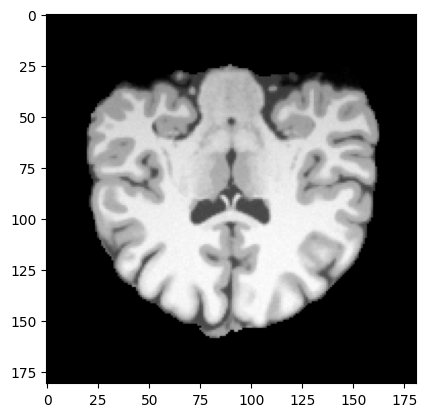

In [6]:
plt.imshow(brain, cmap="gray")

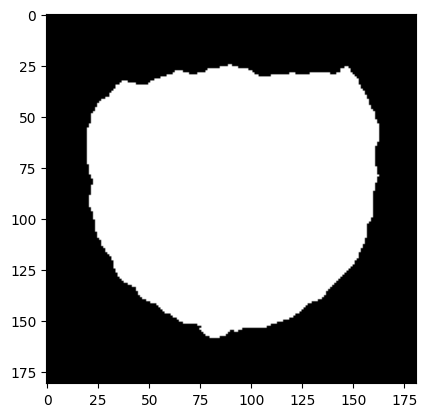

In [19]:
plt.imshow(brain_mask, cmap="gray")

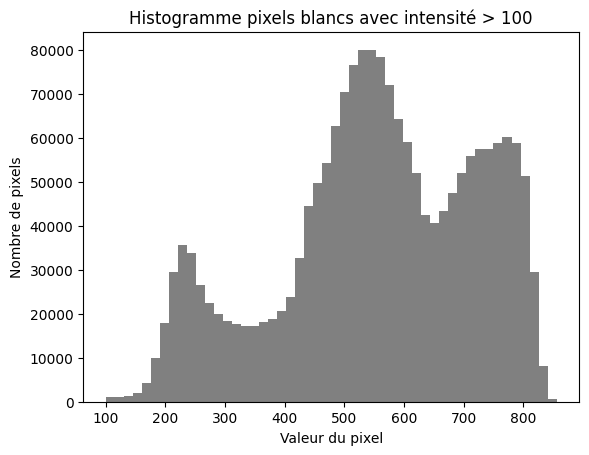

In [7]:
# histogramme de intensitées de chaaque pixel

min_intesity = 100

# filtre pixels blancs ET intensité > 100
pixels = img[(mask > 0) & (img > min_intesity)]

# histogramme
plt.hist(pixels.ravel(), bins=50, color='gray')
plt.title("Histogramme pixels blancs avec intensité > 100")
plt.xlabel("Valeur du pixel")
plt.ylabel("Nombre de pixels")
plt.show()

In [8]:
p = 3 #nombre de classes de gausiennes
mini = pixels.min()
maxi = pixels.max()

# création des paramètres du GMM
moyennes = np.zeros(p)
variances = np.zeros(p)
poids = np.zeros(p)

#initialisation des paramètres 

etendue = maxi - mini 
sigma_0 = etendue/p

for k in range(p): 
    variances[k] = sigma_0 ** 2
    poids[k] = 1/p
    moyennes[k] = mini + (k+1)*sigma_0 


In [26]:

def hist_scale(pixels, delta, poids, moyennes, variances): 
    # histogramme brut
    hauteurs, pas, _ = plt.hist(pixels, bins=delta, color='gray', alpha=0.6)

    # axe des intensités
    x = np.linspace(pixels.min(), pixels.max(), 1000)

    # facteur d'échelle pour que les densités soient cohérentes avec l'histogramme non normalisé 
    scale = len(pixels) * delta # = aire de l'histogramme car = somme h(i) x delta = delta x somme h(i) = delta x len(pixels) par def d'un histogramme

    #Superposition des gausiennes initiales à l'histogramme 


    y_gmm = np.zeros_like(x)

    for k in range(p): 
        y = poids[k] * norm.pdf(x, moyennes[k], np.sqrt(variances[k])) * scale 
        plt.plot(x, y, label=f"Gaussienne {k+1}")
        y_gmm += poids[k]*y

    plt.plot(x, y_gmm, 'k--', linewidth=2, label="mélange")

    plt.title("Histogramme + mélange de gaussiennes initialisées")
    plt.xlabel("Valeur du pixel")
    plt.ylabel("Nombre de pixels")
    plt.legend()
    plt.show()
    


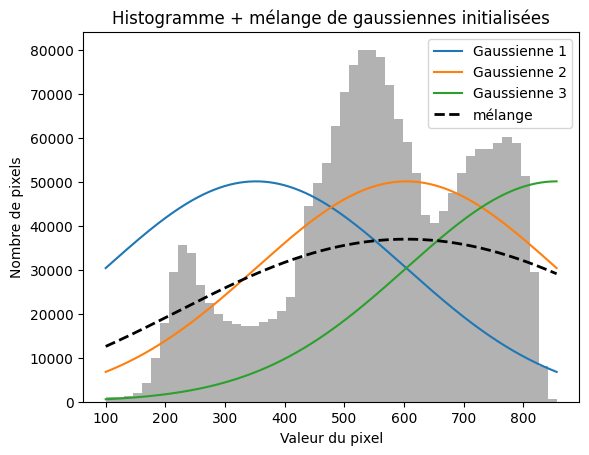

In [27]:
hist_scale(pixels.ravel(), 50, poids, moyennes, variances)

In [51]:
min_intensity = 90
def plot_image_3_classes_em(image, mask, q, iteration, colors=["yellow", "green", "red"], title="Segmentation EM"):
    """
    Affiche l'image segmentée selon les 3 classes EM.
    Chaque pixel prend la couleur de la classe la plus probable.
    """
    # initialisation de l'image segmentée
    H, W = image.shape
    img_rgb = np.zeros((H, W, 3), dtype=np.float32)
    
    # nombre de classes (d'après les poids globaux)
    p = len(poids)

    # classe la plus probable pour chaque pixel valide
    classes = np.argmax(q, axis=1)
    
    # dictionnaire des couleurs RGB
    color_rgb_map = {
        "yellow": [1, 1, 0],
        "green": [0, 1, 0],
        "red": [1, 0, 0]
    }
    
    # assigner les couleurs aux pixels dans le masque
    for i, color in enumerate(colors):
        img_rgb[(mask > 0) & (classes == i)] = color_rgb_map[color]
    
    # pixels hors masque = noir
    img_rgb[mask == 0] = 0

    # titre avec numéro d'itération
    full_title = f"{title}" + (f" - itération {iteration}" if iteration is not None else "")
    
    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title(full_title)
    plt.axis("off")
    plt.show()


In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def plot_em_iteration2(image, indices, q, iteration, pixels, pi, mu, variances,
                      colors=["yellow", "green", "red"], title="Segmentation EM", delta=50):
    """
    Affiche côte à côte :
    - à gauche : l'image segmentée
    - à droite : histogramme des pixels avec gaussiennes et mélange
    """
    H, W = image.shape
    img_rgb = np.zeros((H, W, 3), dtype=np.float32)

    # classe la plus probable pour chaque pixel
    classes_flat = np.argmax(q, axis=1)

    # couleurs RGB
    color_rgb_map = {
        "yellow": [1, 1, 0],
        "green": [0, 1, 0],
        "red": [1, 0, 0]
    }

    # assigner les couleurs uniquement aux pixels valides
    for k, color in enumerate(colors):
        mask_k = (classes_flat == k)
        img_rgb[indices[0][mask_k], indices[1][mask_k], :] = color_rgb_map[color]

    # pixels hors masque = noir
    img_rgb[image == 0] = 0

    # Figure à 2 sous-plots
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))

    # gauche : segmentation
    axs[0].imshow(img_rgb)
    axs[0].set_title(f"{title} - itération {iteration}")
    axs[0].axis("off")

    # droite : histogramme + gaussiennes
    axs[1].hist(pixels, bins=delta, color='gray', alpha=0.6)

    x = np.linspace(pixels.min(), pixels.max(), 1000)
    scale = len(pixels) * (pixels.max() - pixels.min()) / delta
    y_gmm = np.zeros_like(x)
    p = len(pi)
    for k in range(p):
        y = pi[k] * norm.pdf(x, mu[k], np.sqrt(variances[k])) * scale
        axs[1].plot(x, y, label=f"Gaussienne {k+1}")
        y_gmm += y
    axs[1].plot(x, y_gmm, 'k--', linewidth=2, label="Mélange")

    axs[1].set_title("Histogramme + mélange de gaussiennes")
    axs[1].set_xlabel("Valeur du pixel")
    axs[1].set_ylabel("Nombre de pixels")
    axs[1].legend()

    plt.tight_layout()
    plt.show()


def em_gmm_image2(image, mask, p=3, min_intensity=100, max_iter=50, epsilon=1e-3):
    """
    Applique l'algorithme EM pour un GMM sur les pixels valides d'une image.
    
    Retourne :
    - q : responsabilités finales (n_pixels x p)
    - poids : poids finaux
    - moyennes : moyennes finales
    - variances : variances finales
    """
    # 1. Extraire les pixels valides
    valid_mask = (mask > 0) & (image > min_intensity)
    pixels = image[valid_mask].astype(float)
    indices = np.where(valid_mask)
    n_pixels = len(pixels)
    if n_pixels == 0:
        raise ValueError("Aucun pixel valide trouvé dans le masque et seuil donné.")
    
    mini, maxi = pixels.min(), pixels.max()

    # 2. Initialisation des paramètres
    moyennes = np.zeros(p)
    variances = np.zeros(p)
    poids = np.zeros(p)

    etendue = maxi - mini
    sigma_0 = etendue / p

    for k in range(p): 
        variances[k] = sigma_0 ** 2
        poids[k] = 1/p
        moyennes[k] = mini + (k+1)*sigma_0 
    
    # 3. Boucle EM
    for it in range(1, max_iter+1):
        # E-step : calcul des responsabilités q_{ik}
        q = np.zeros((n_pixels, p))
        for k in range(p):
            q[:, k] = poids[k] * norm.pdf(pixels, moyennes[k], np.sqrt(variances[k]))
        q_sum = np.sum(q, axis=1, keepdims=True)
        q /= q_sum  # normalisation

        # M-step : mise à jour des paramètres
        N = np.sum(q, axis=0)  # somme sur i pour chaque k
        moyennes_new = np.sum(q * pixels[:, None], axis=0) / N
        variances_new = np.sum(q * (pixels[:, None] - moyennes_new) ** 2, axis=0) / N
        poids_new = N / n_pixels

        # Vérifier la convergence
        delta_mu = np.max(np.abs(moyennes_new - moyennes))
        delta_sigma = np.max(np.abs(np.sqrt(variances_new) - np.sqrt(variances)))
        delta_pi = np.max(np.abs(poids_new - poids))

        # Plot intermédiaire
        plot_em_iteration2(image, indices, q, it, pixels, poids_new, moyennes_new, variances_new,
                          ["yellow", "green", "red"], "Segmentation EM", 50)
        
        if max(delta_mu, delta_sigma, delta_pi) < epsilon:
            break

        # Mise à jour pour la prochaine itération
        moyennes, variances, poids = moyennes_new, variances_new, poids_new
    
    return q, poids, moyennes, variances




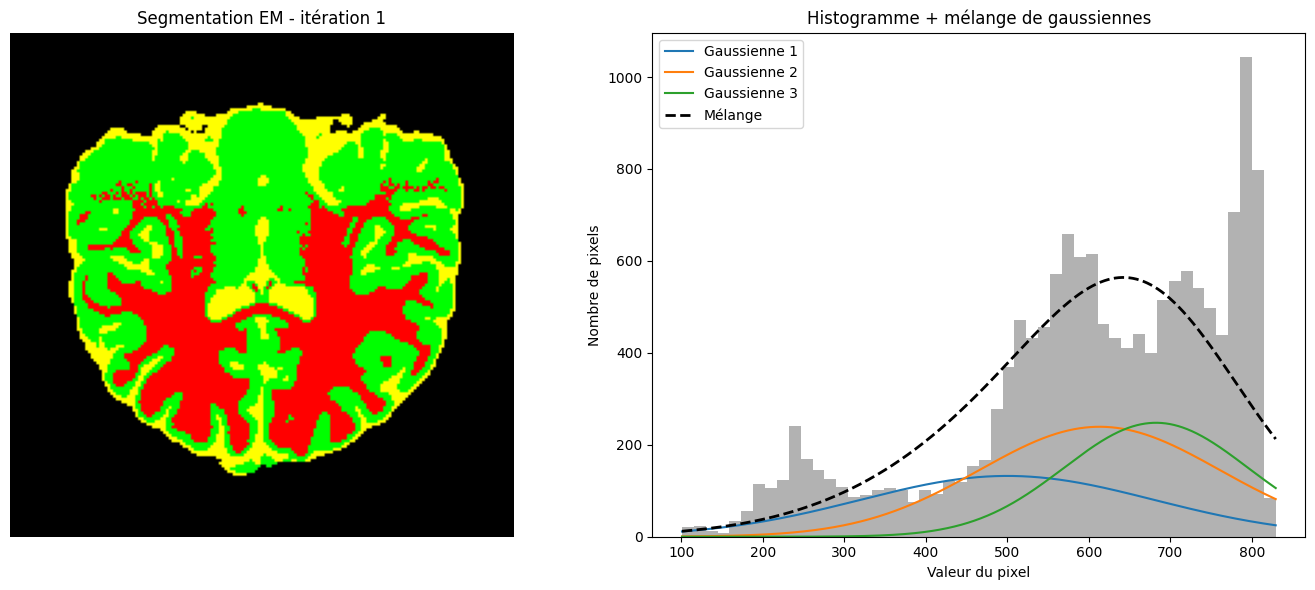

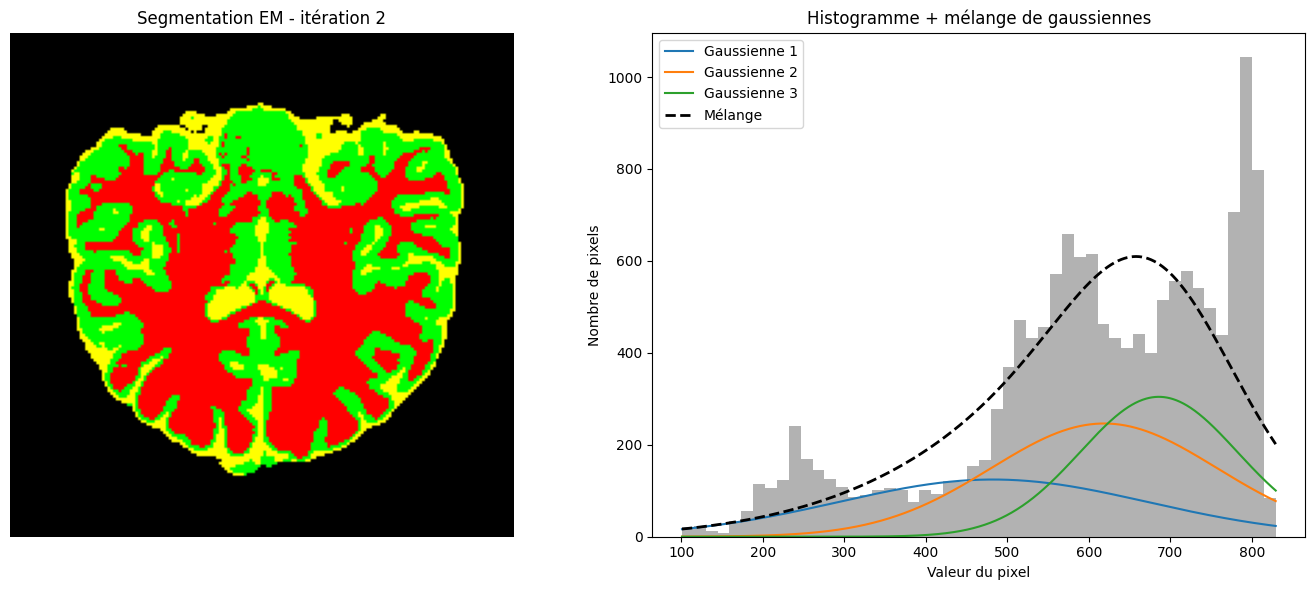

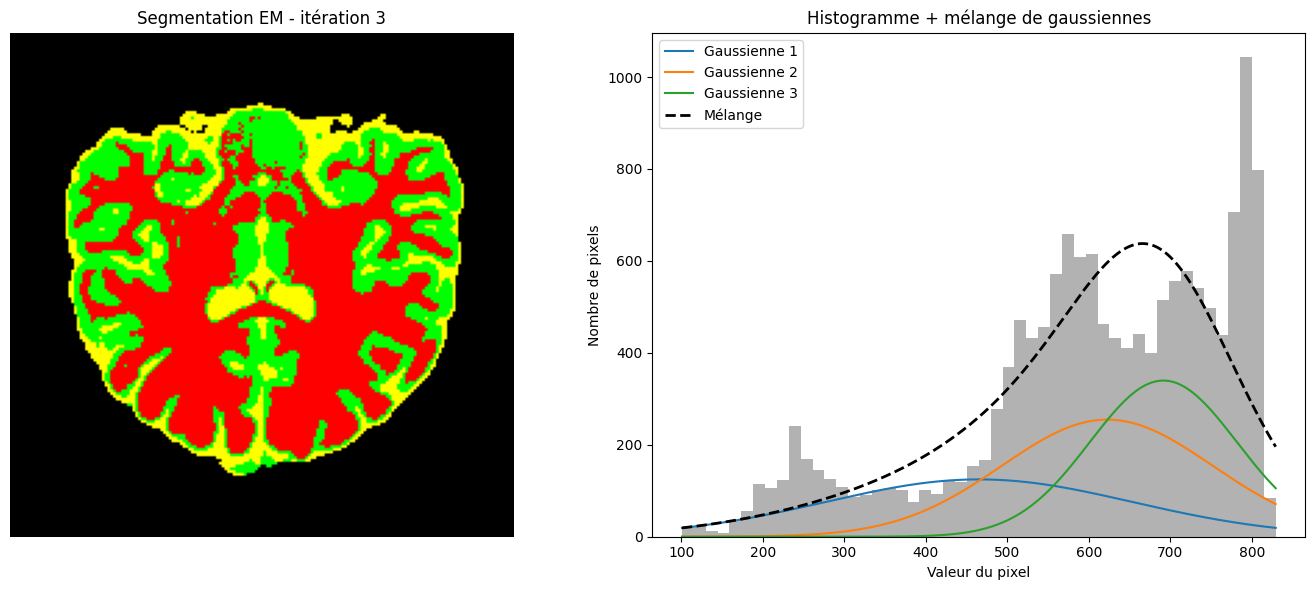

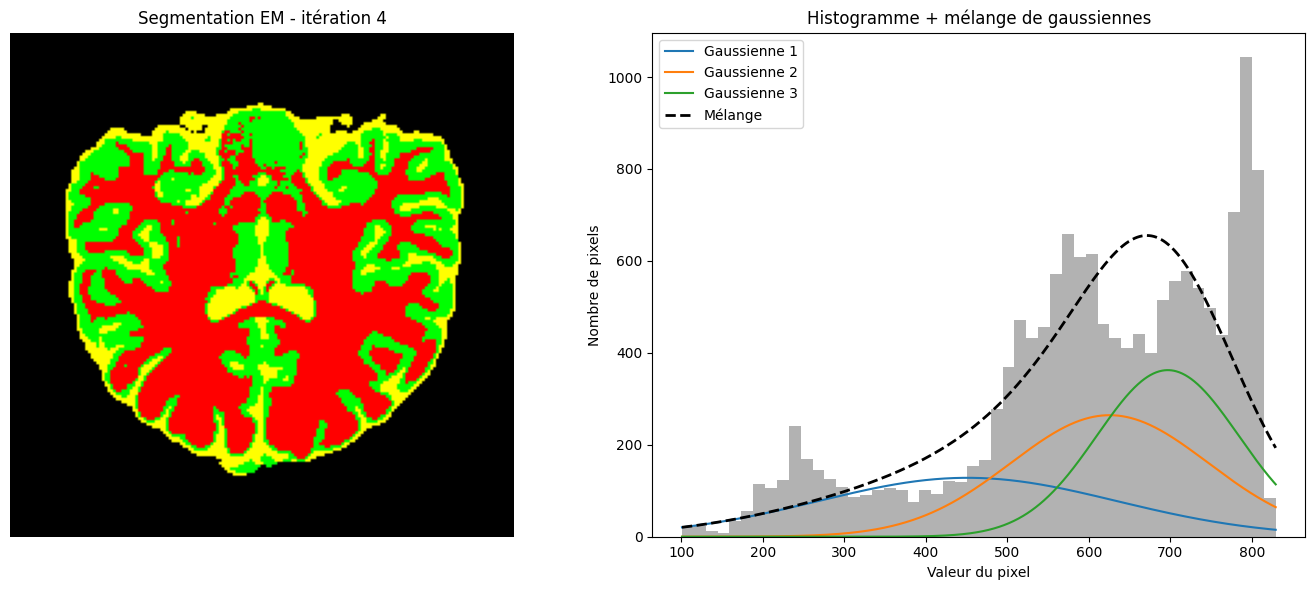

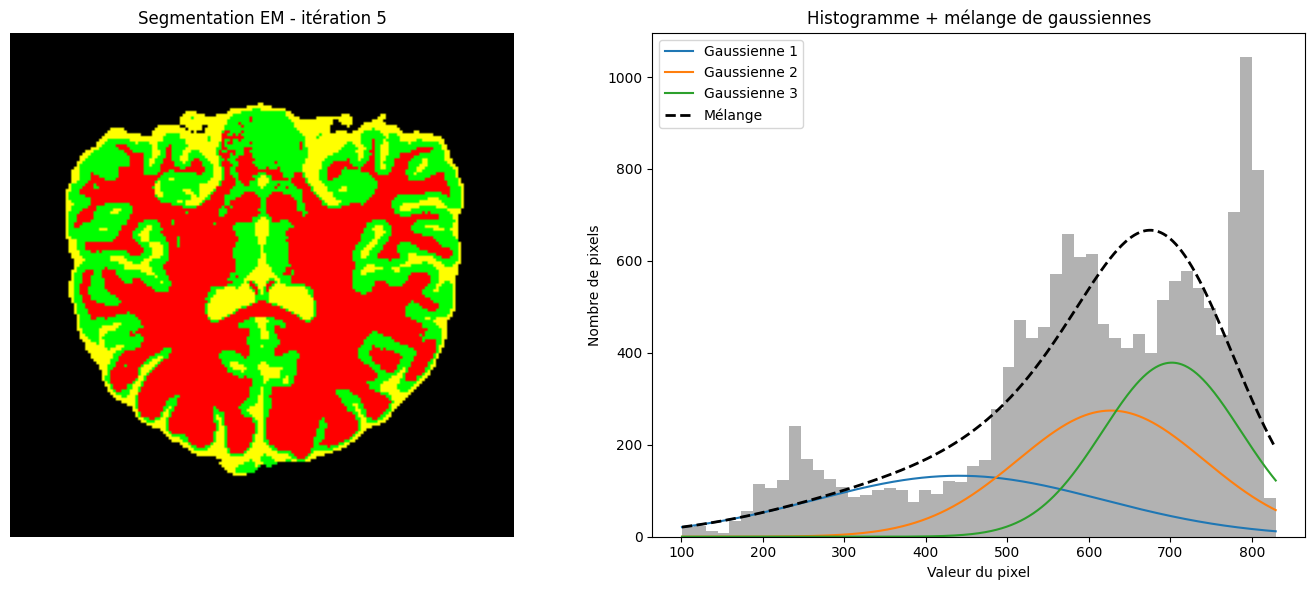

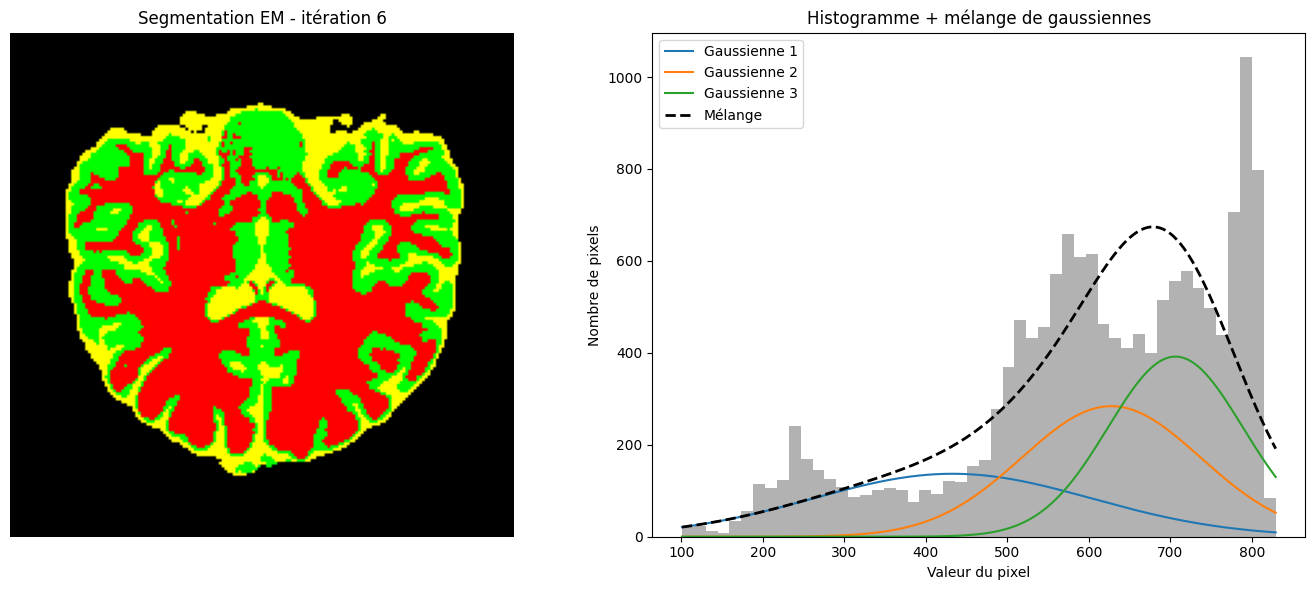

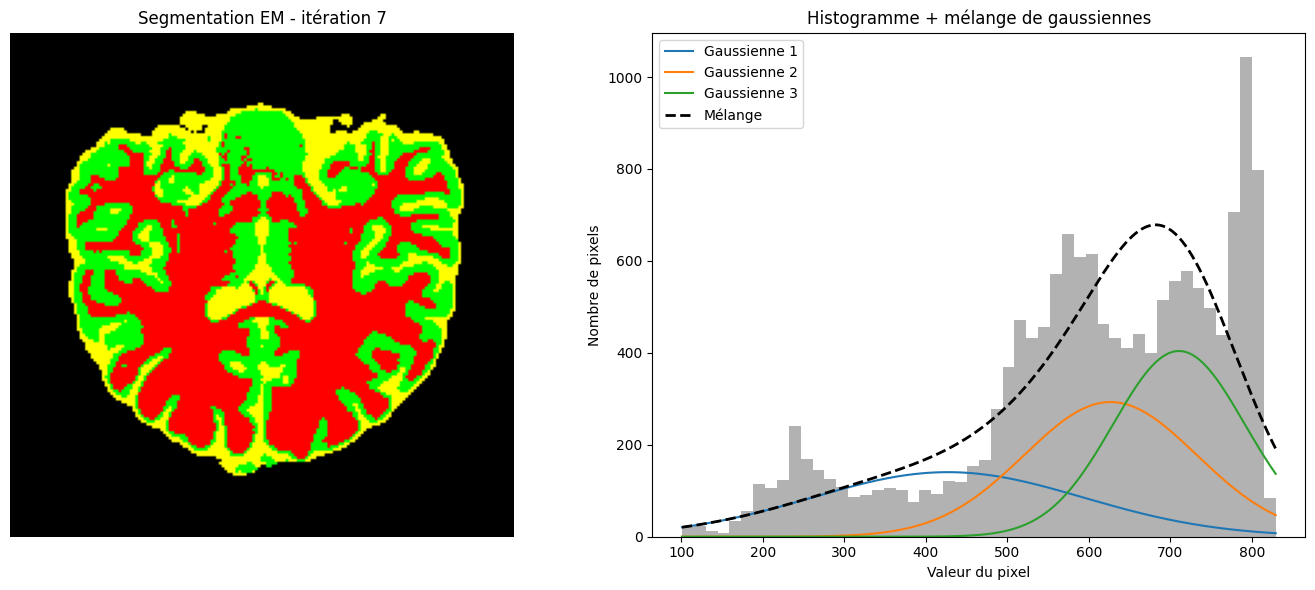

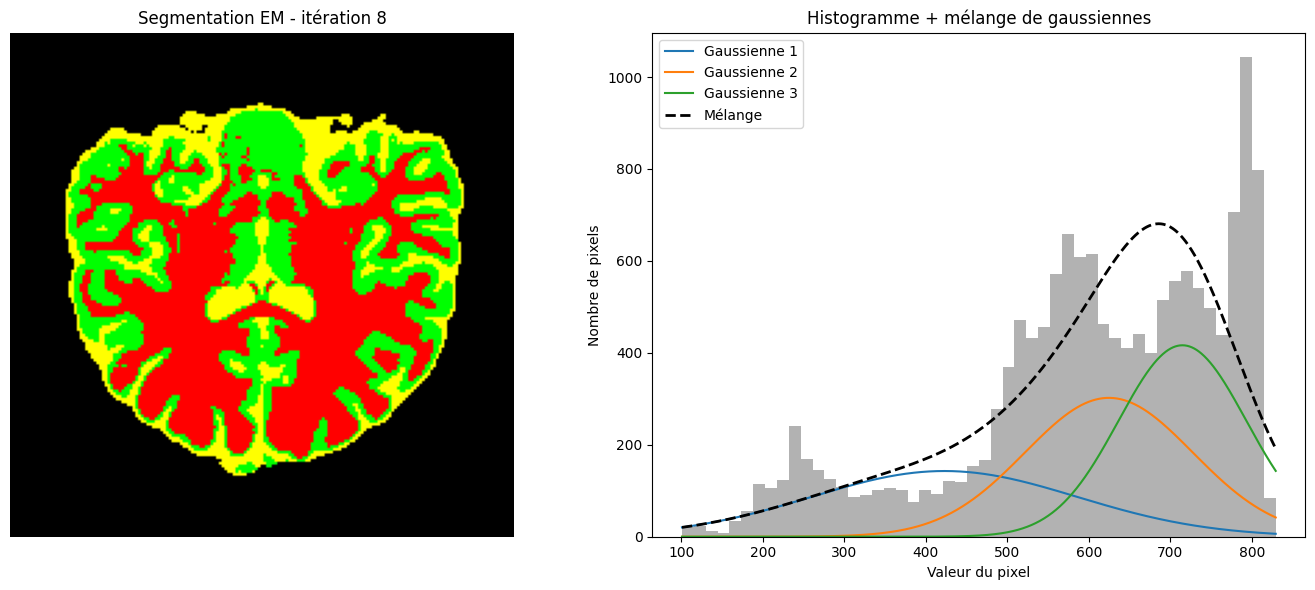

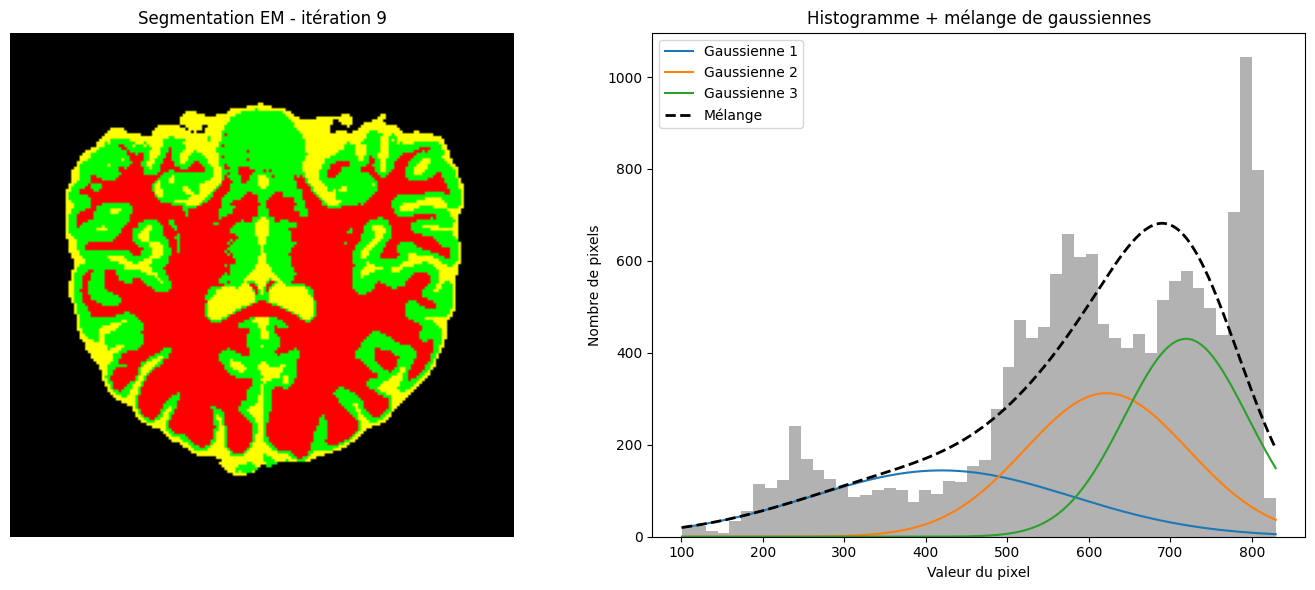

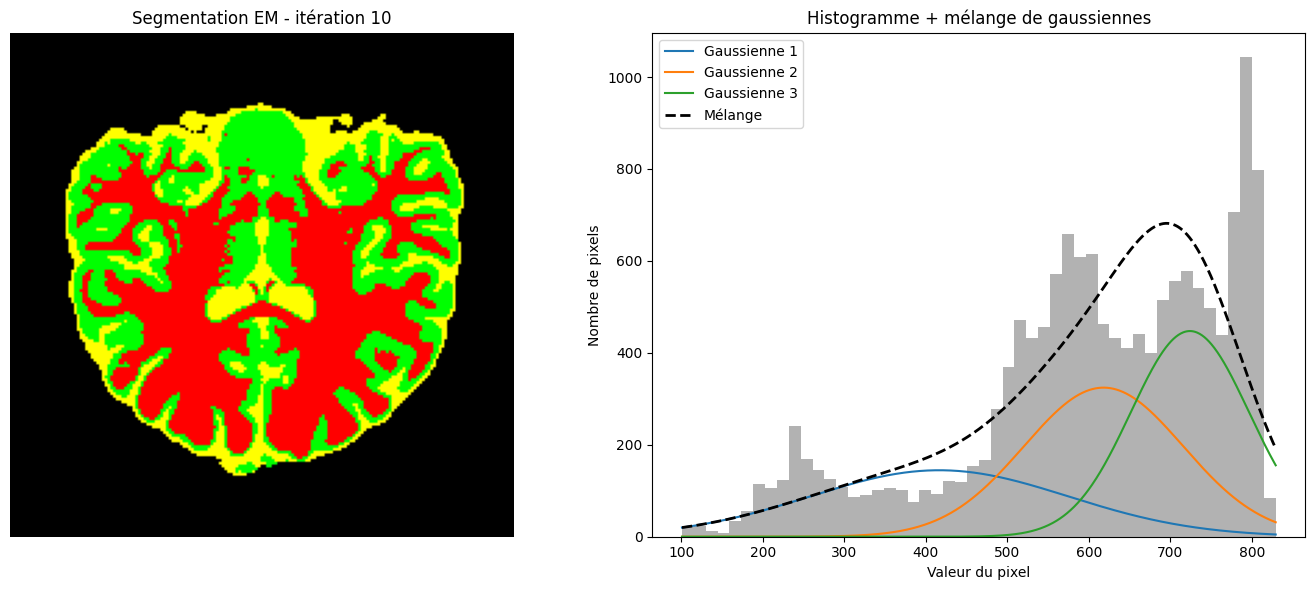

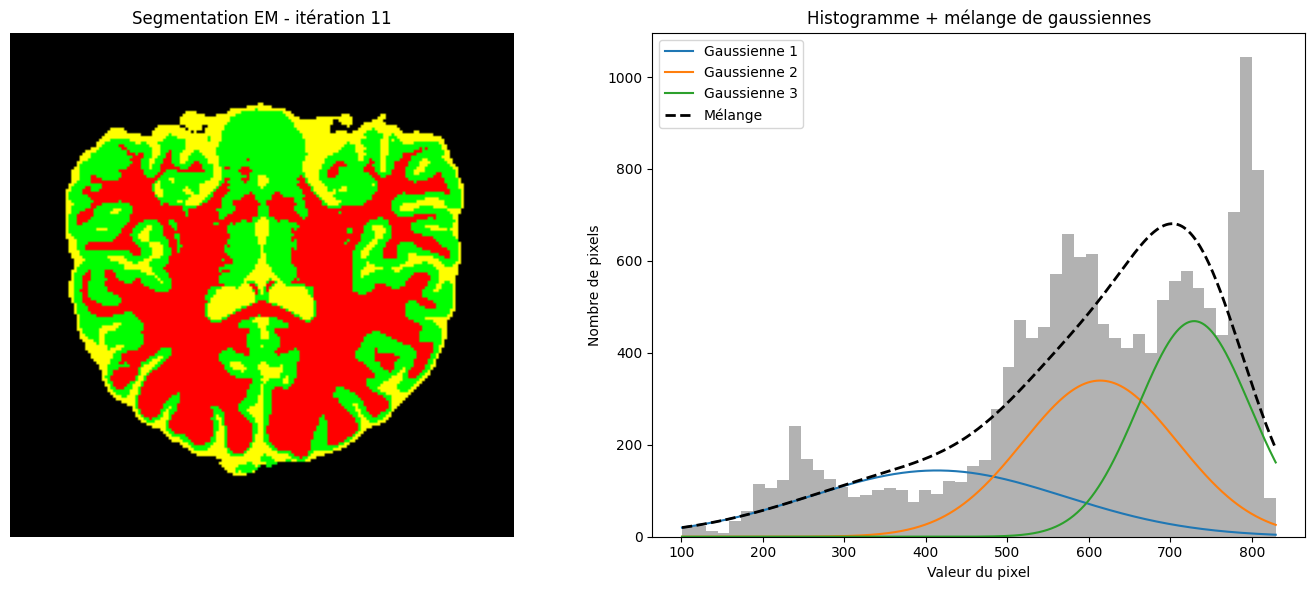

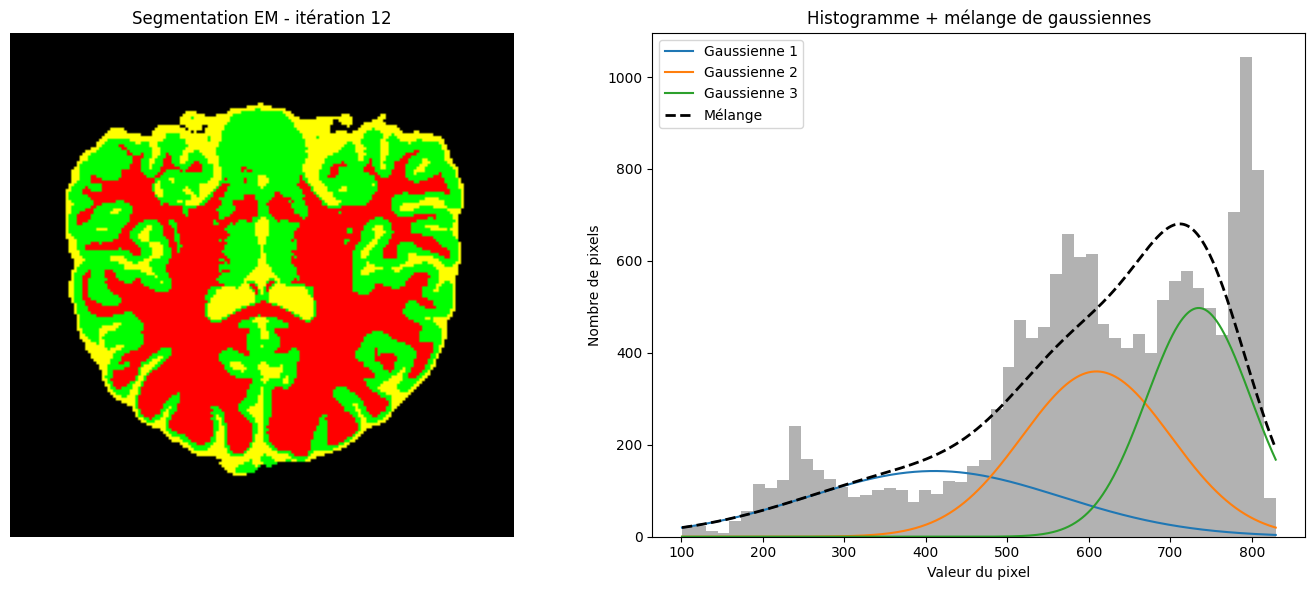

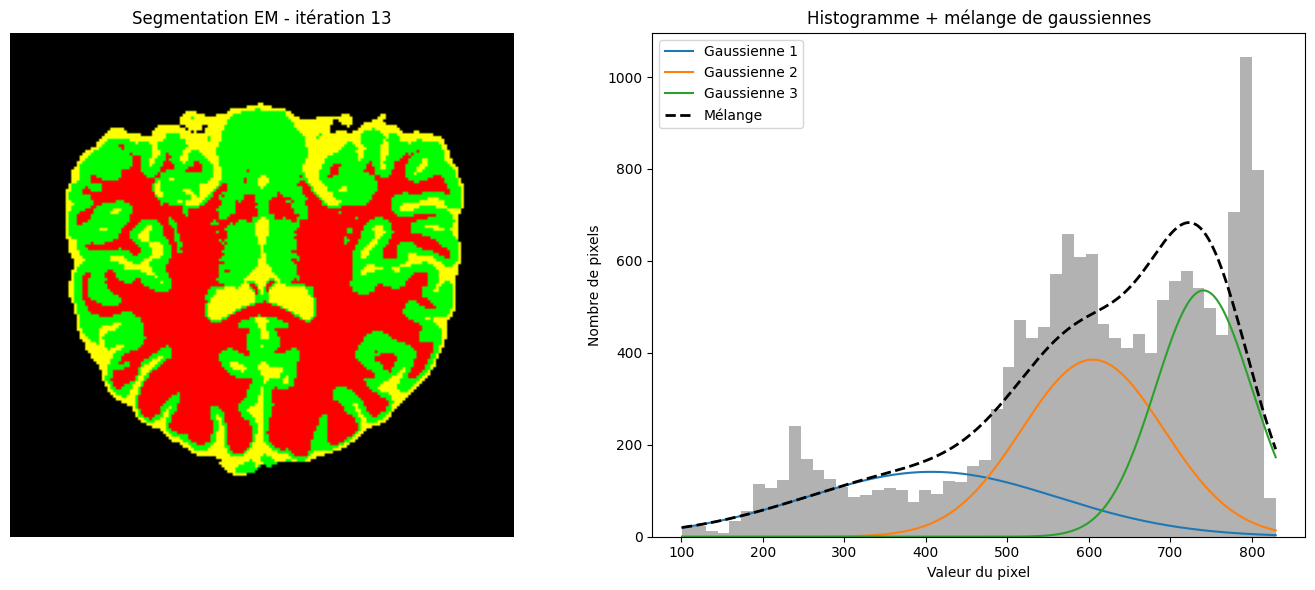

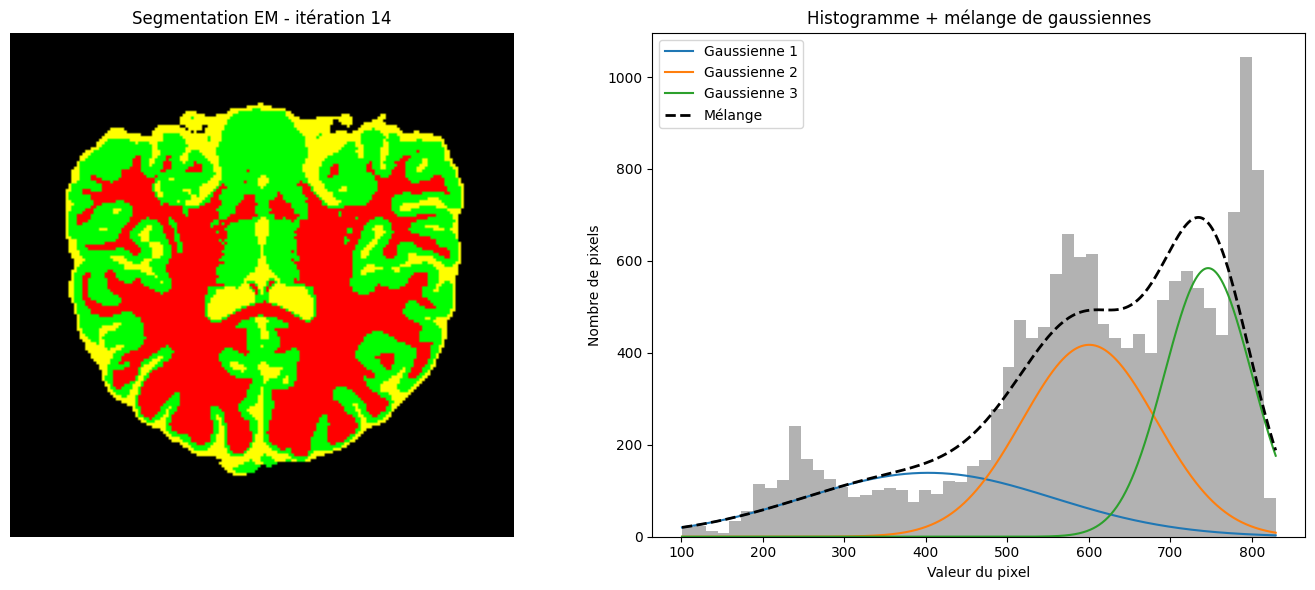

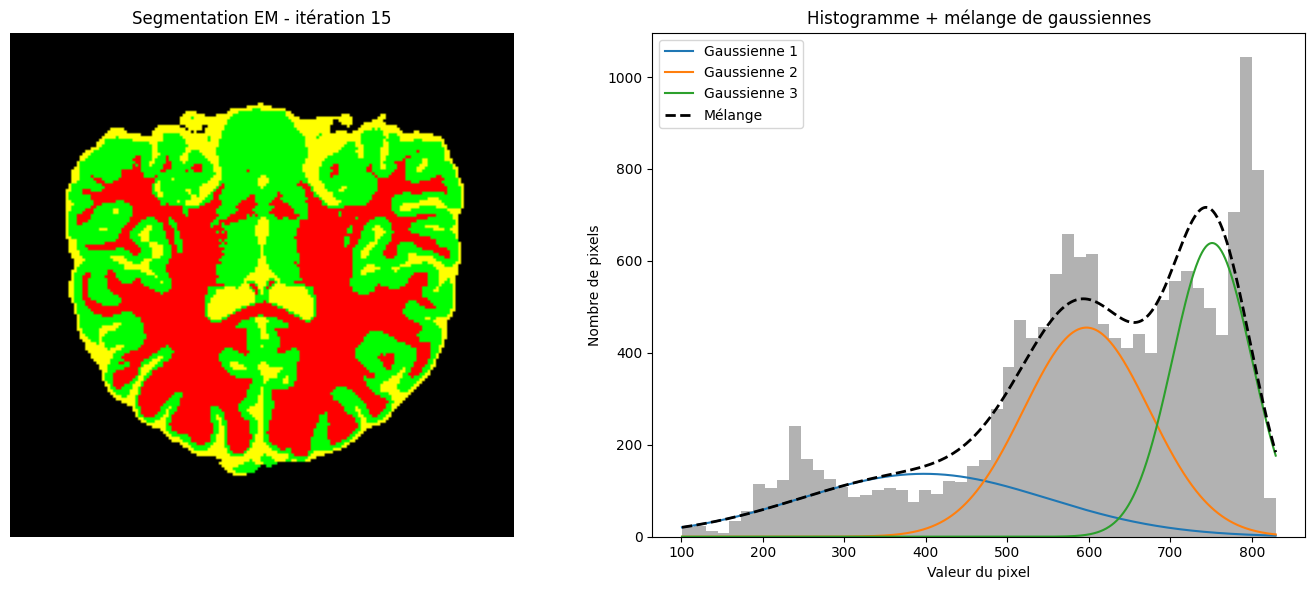

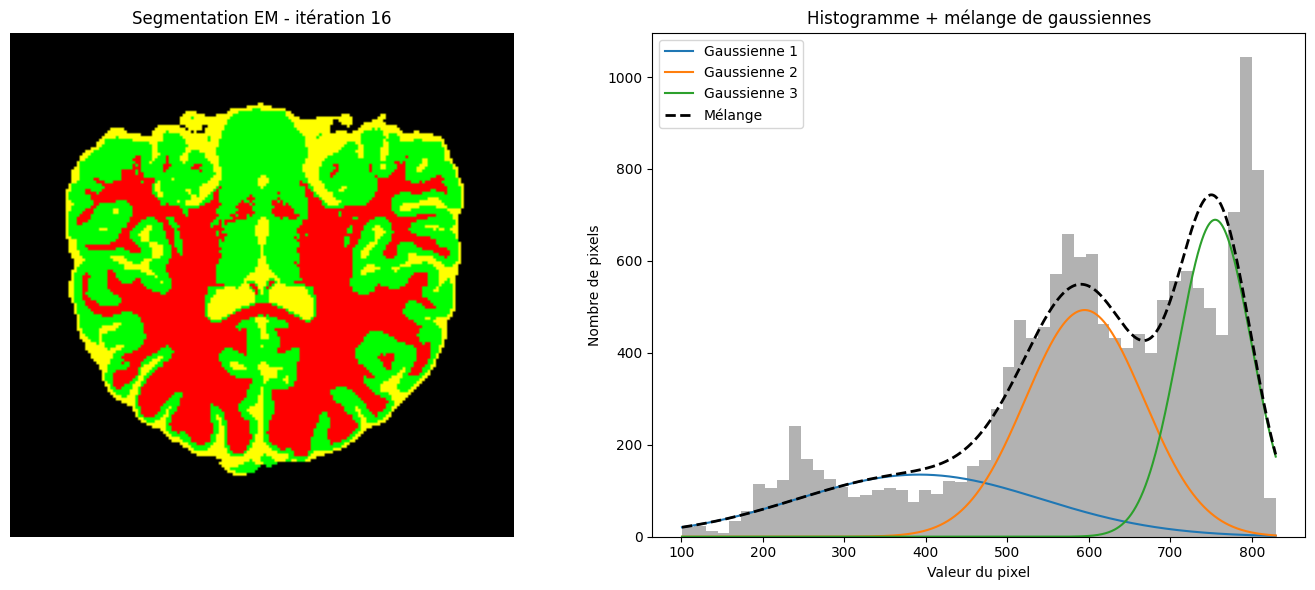

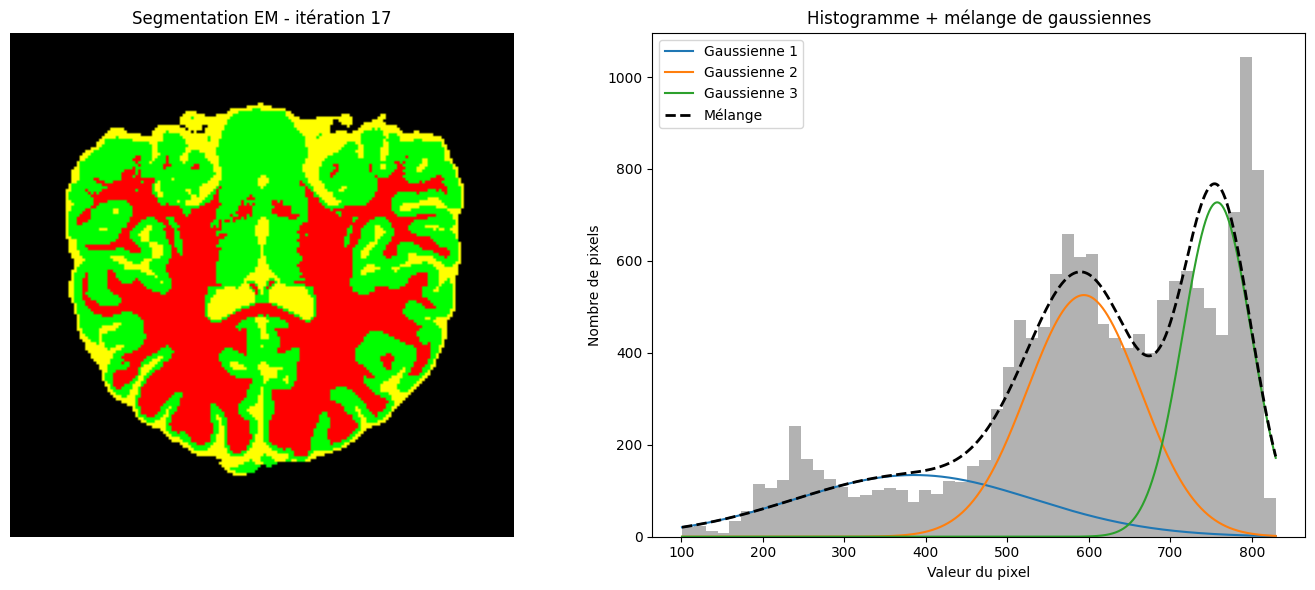

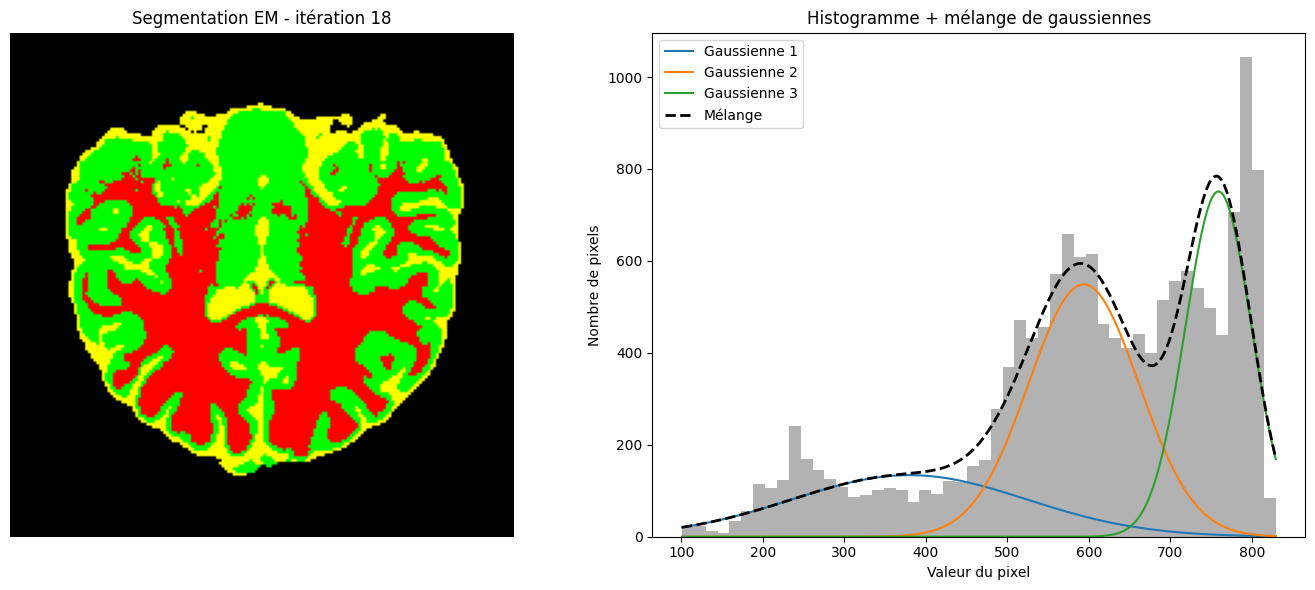

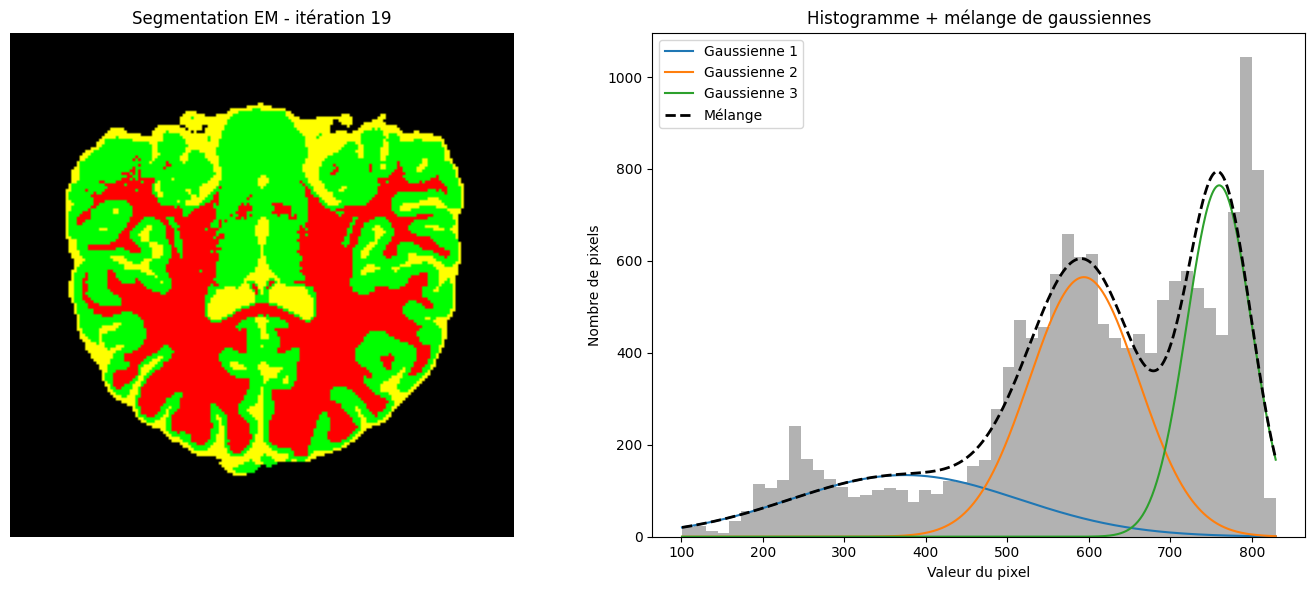

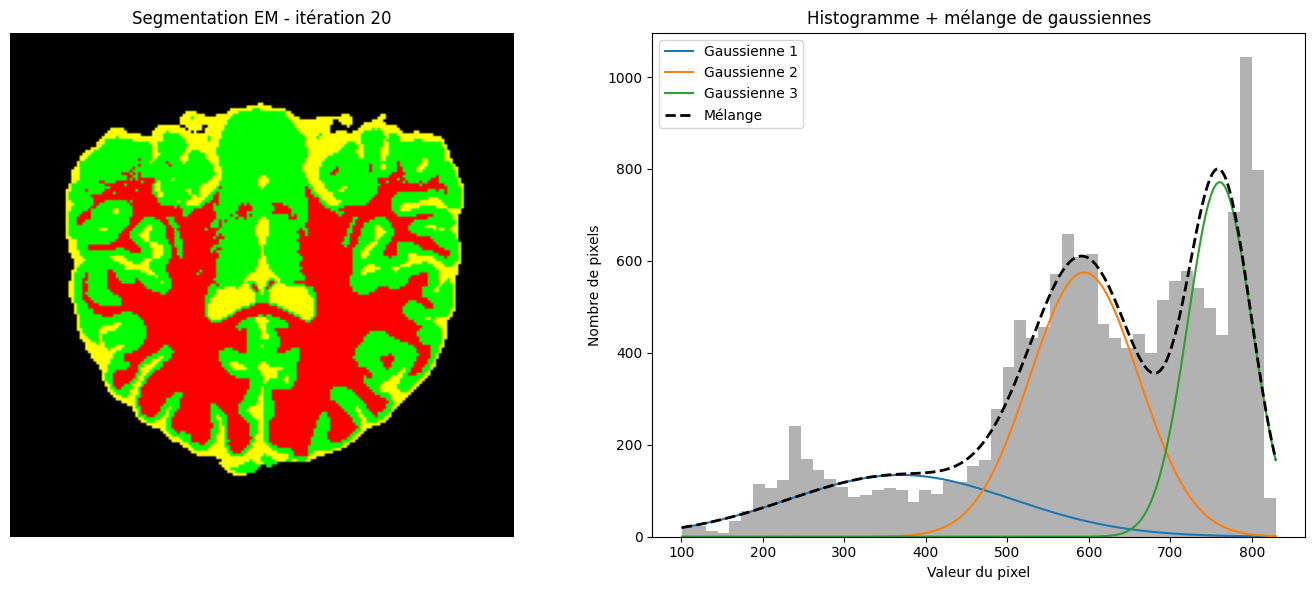

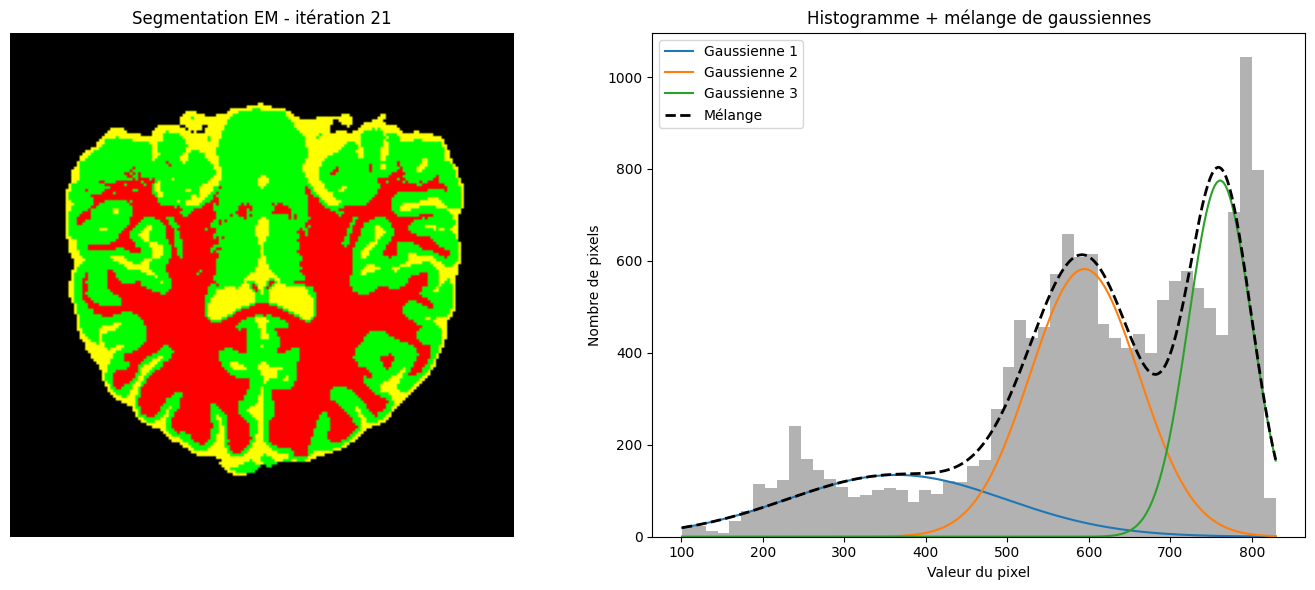

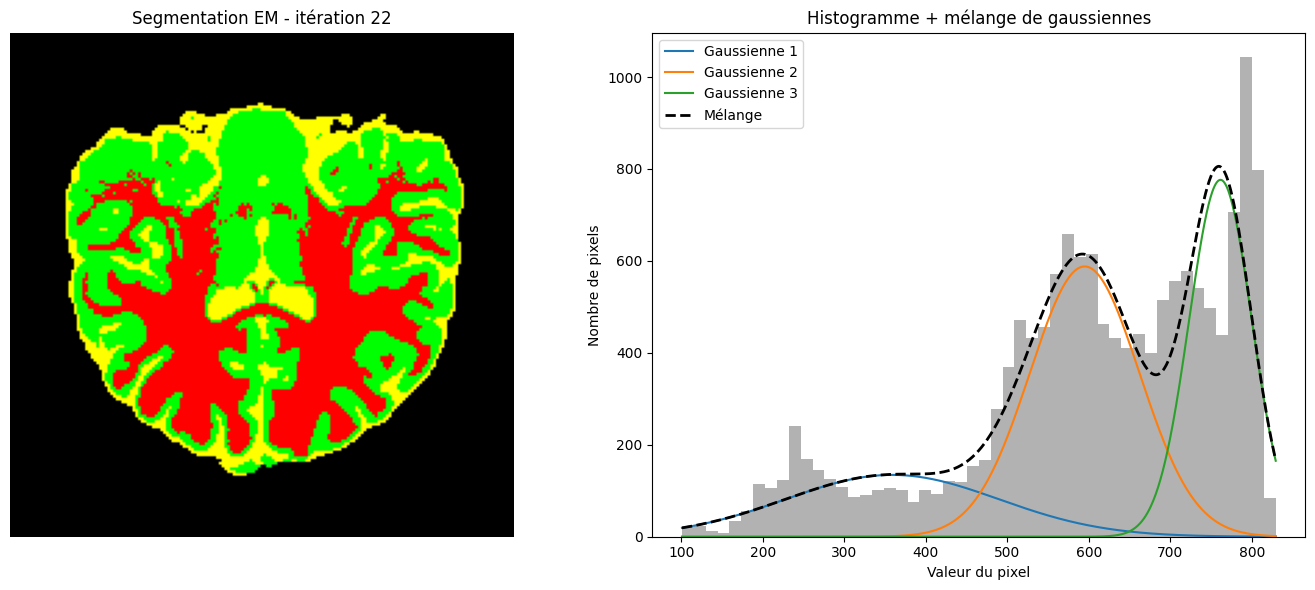

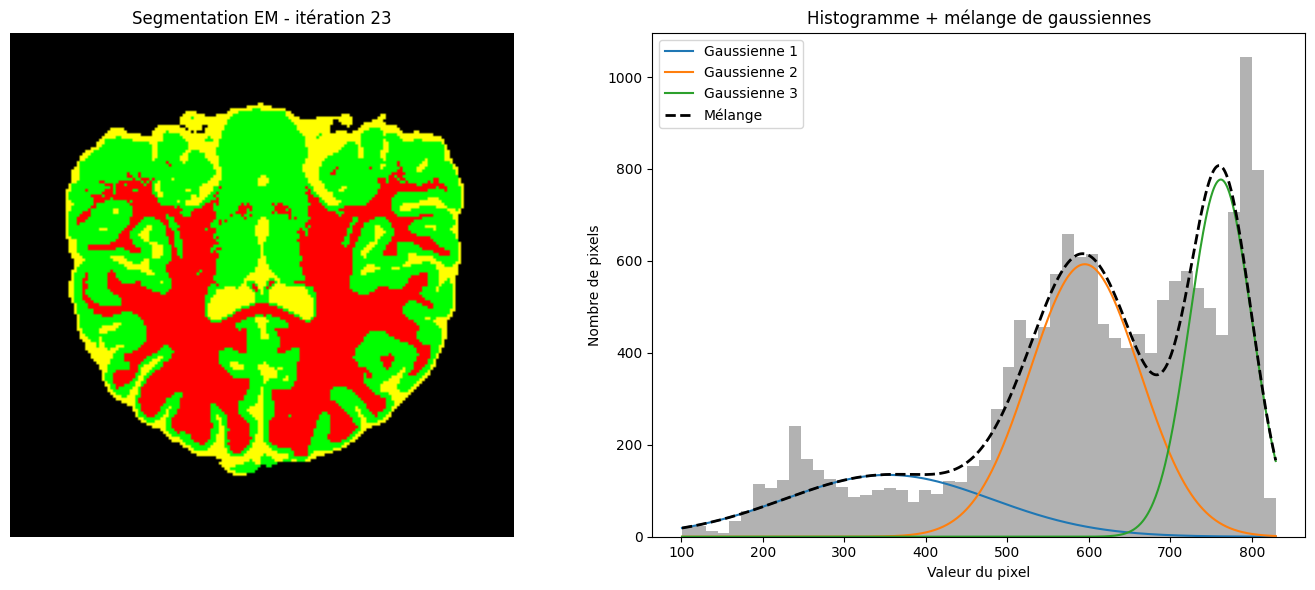

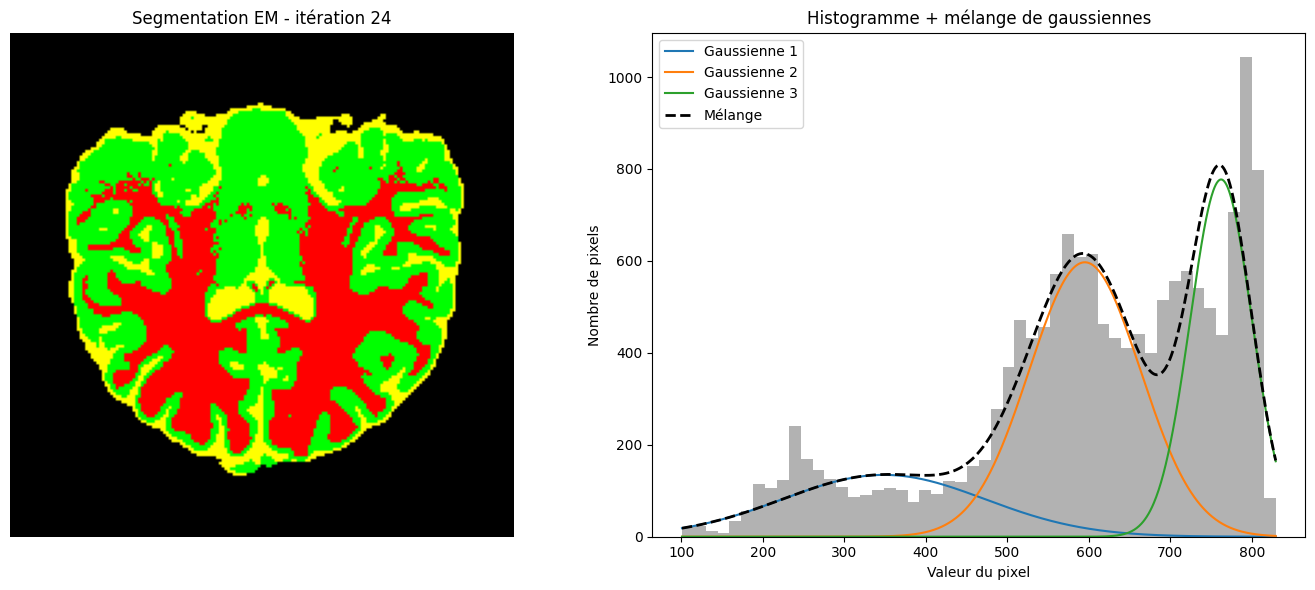

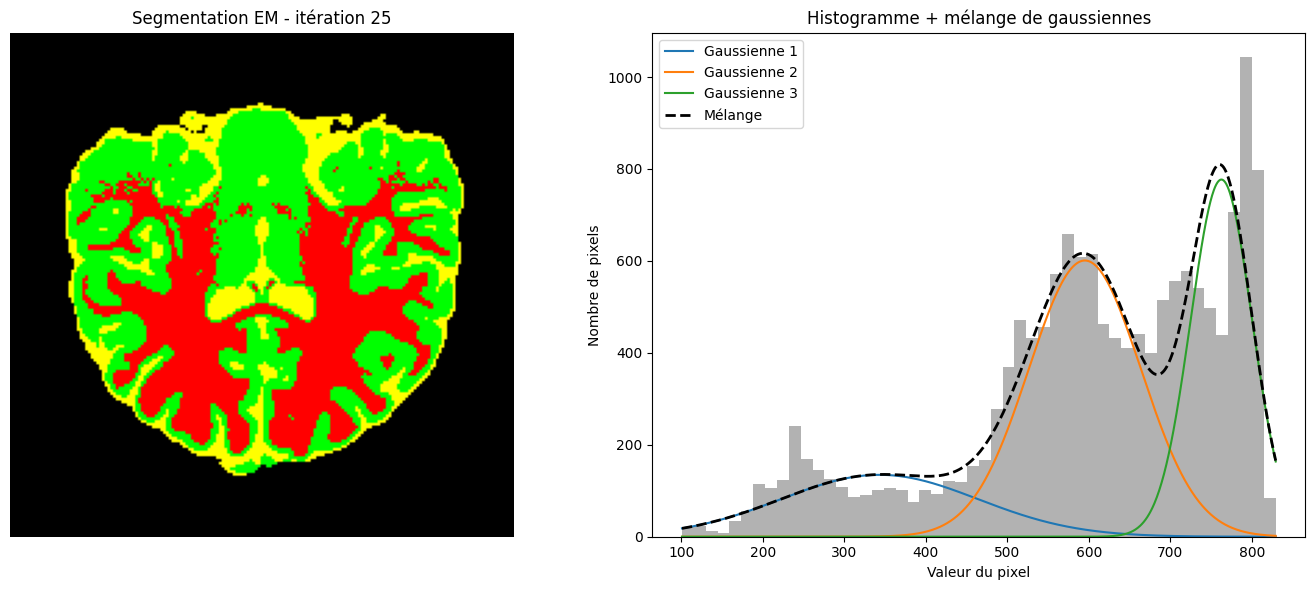

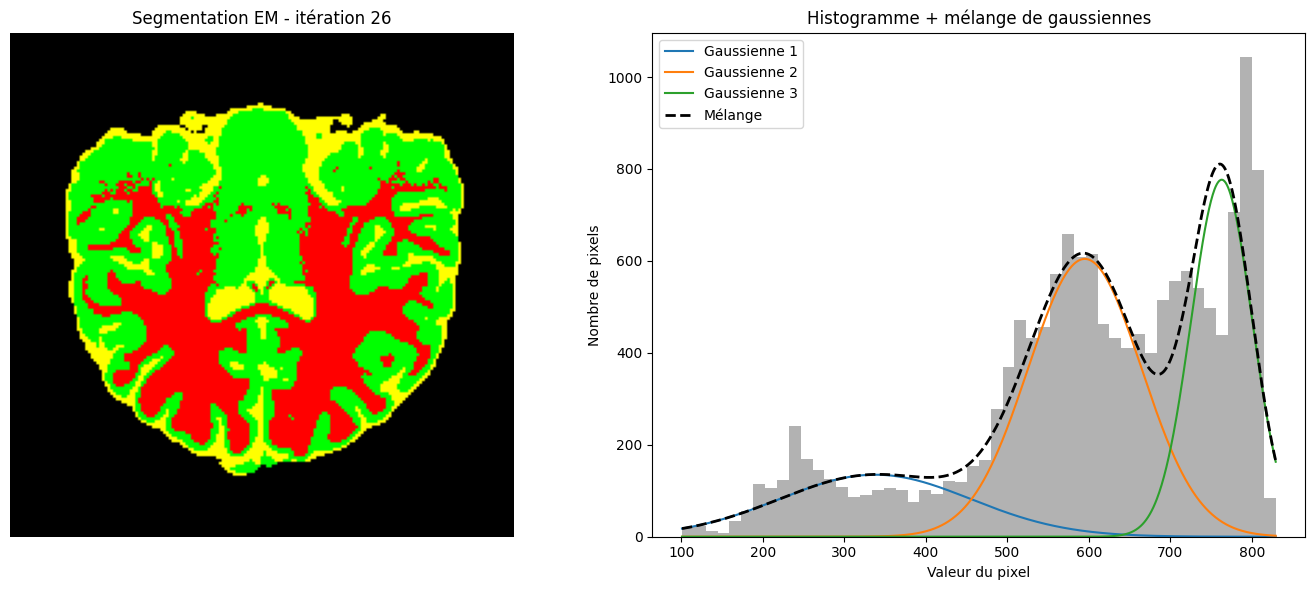

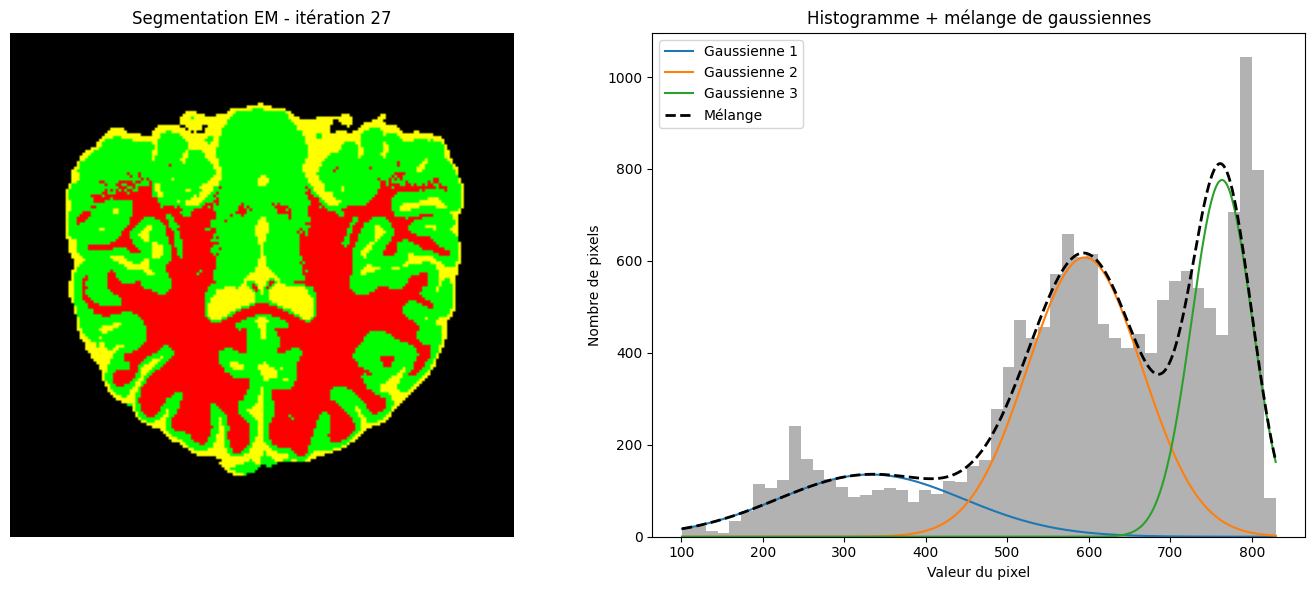

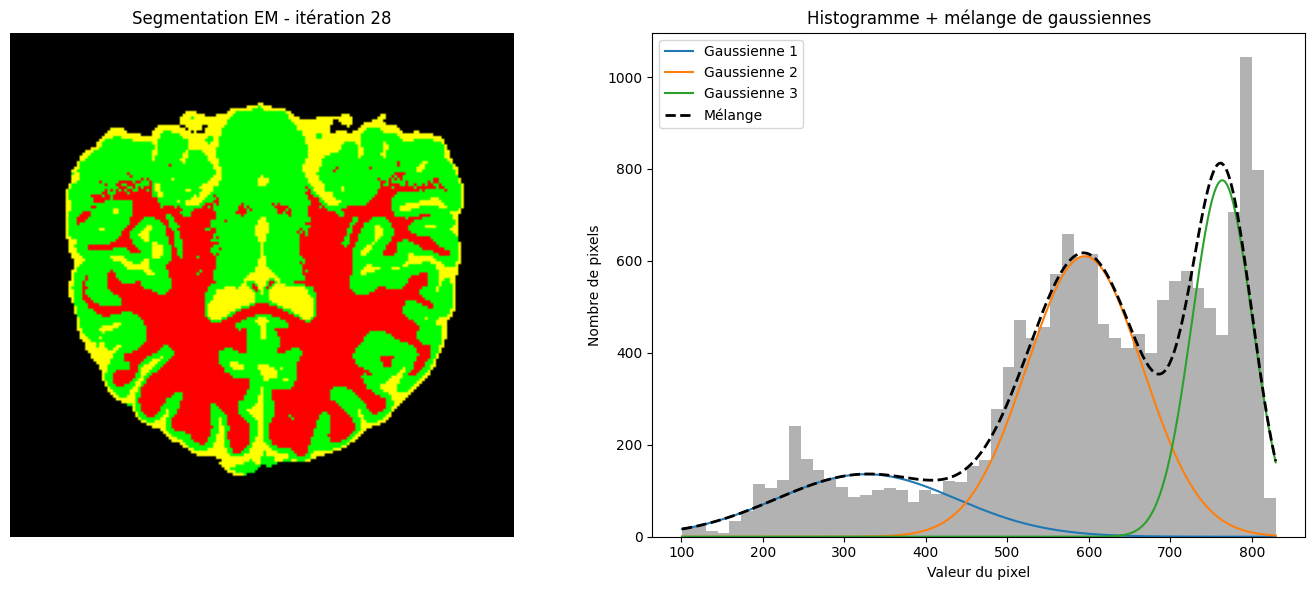

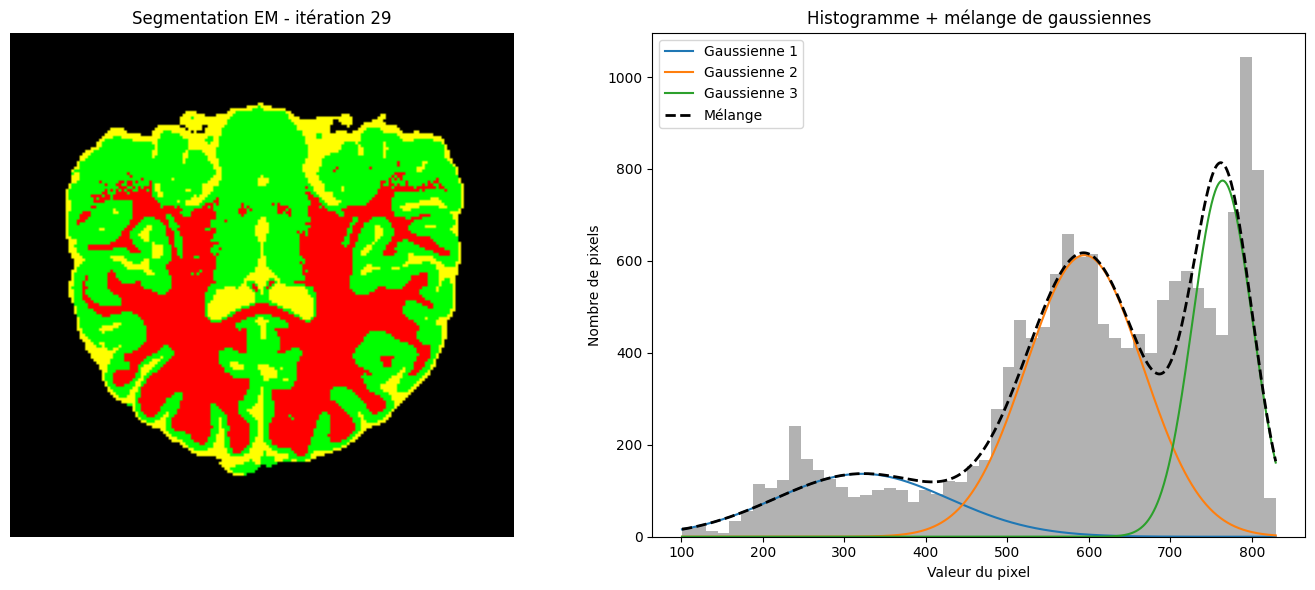

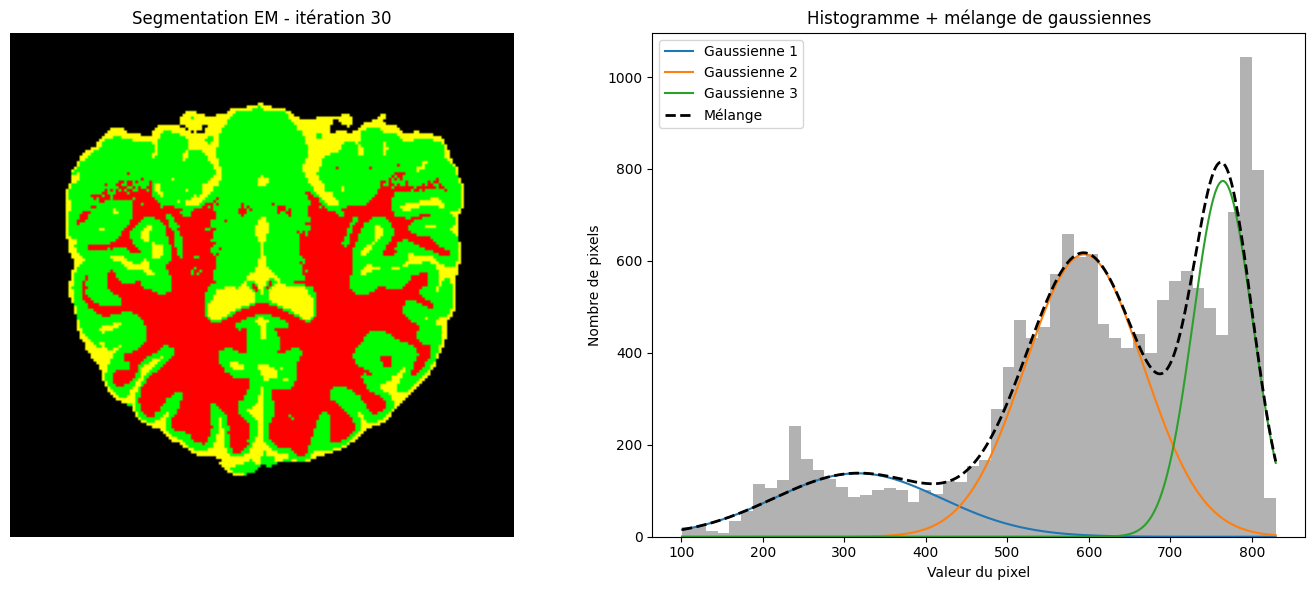

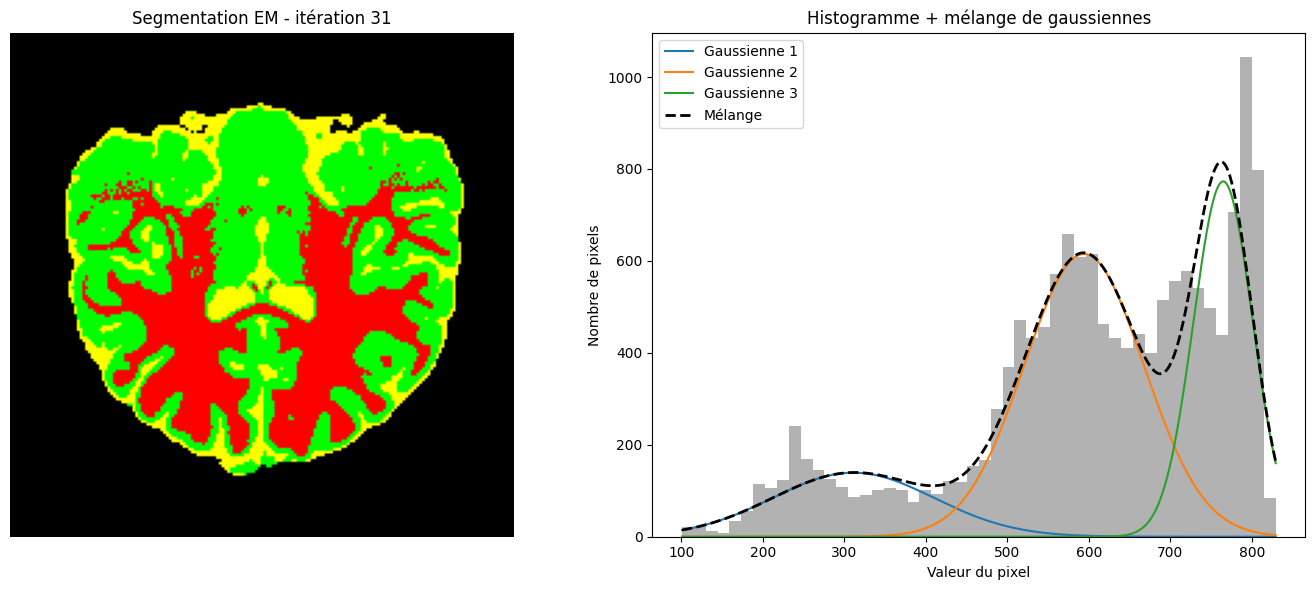

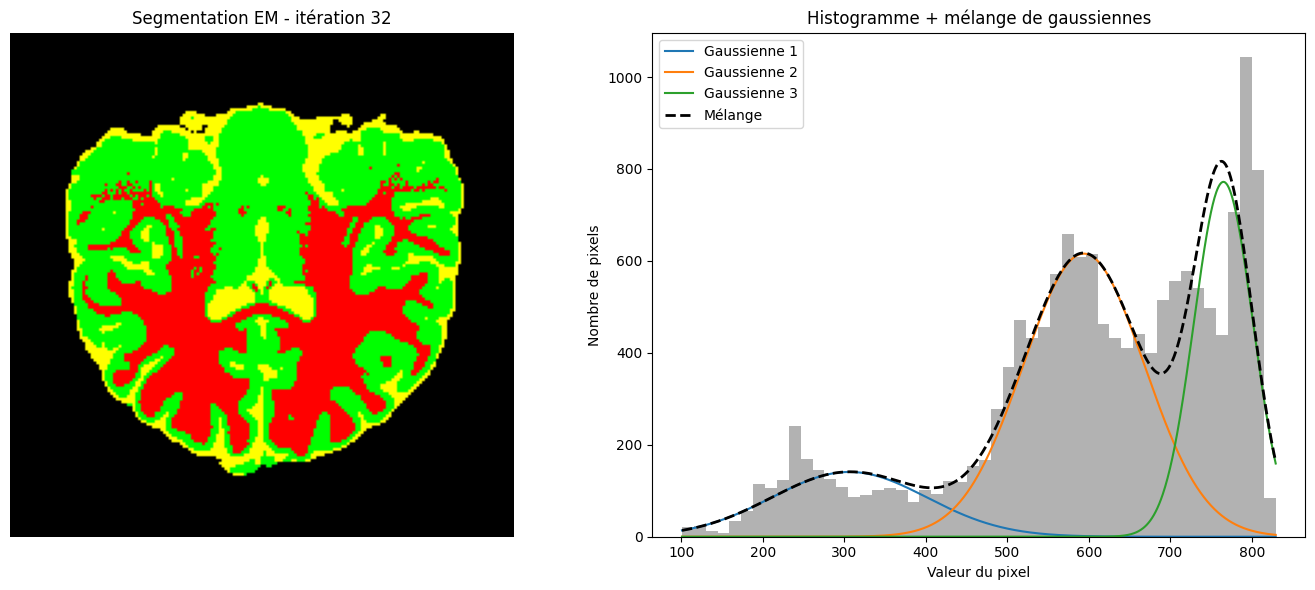

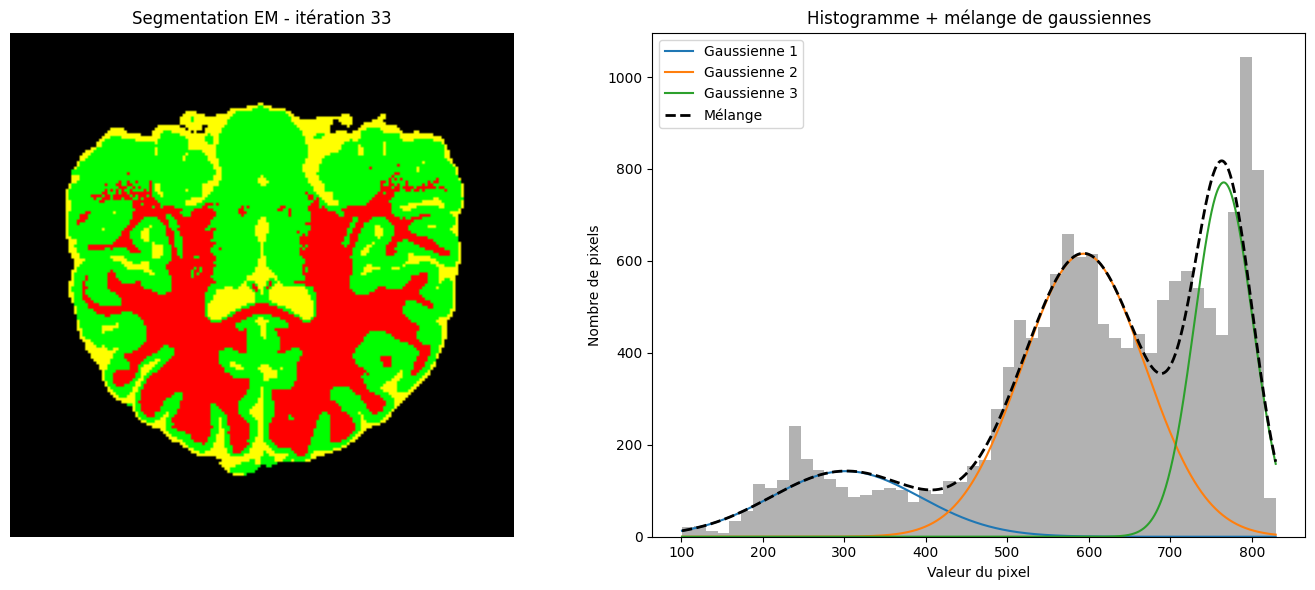

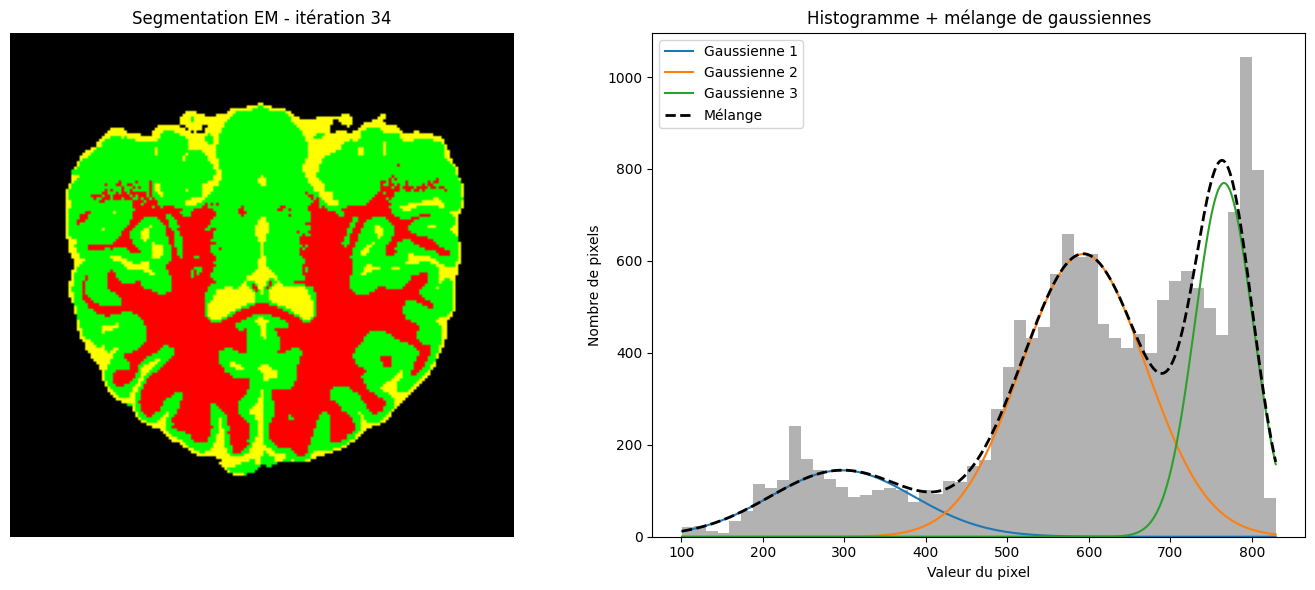

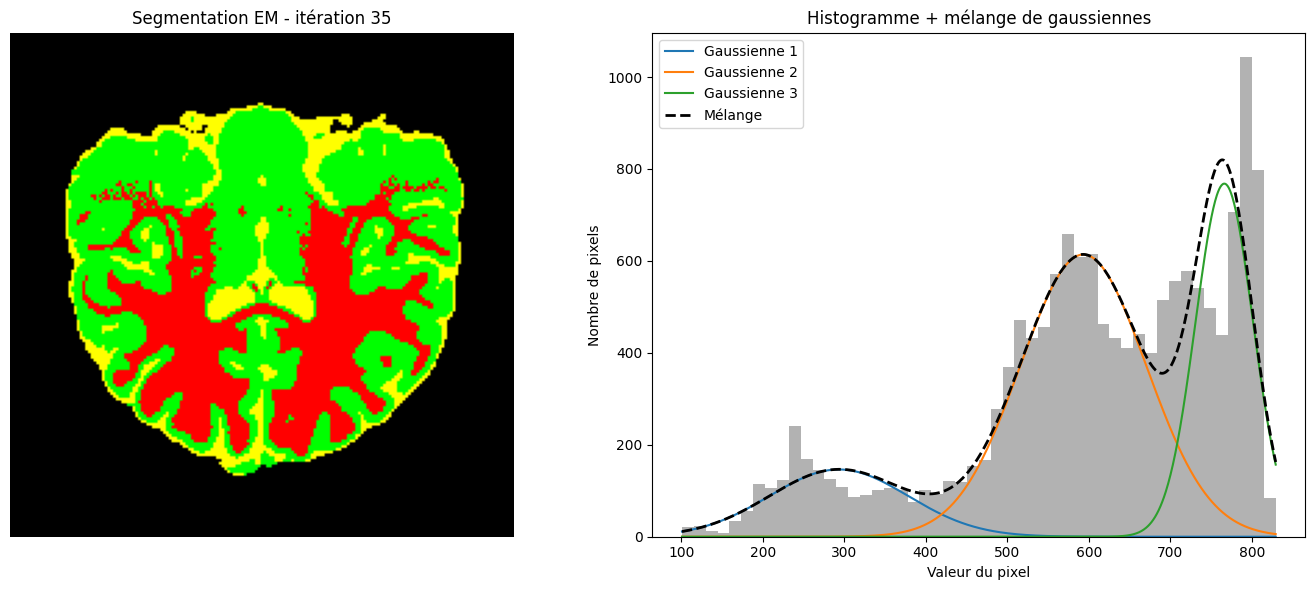

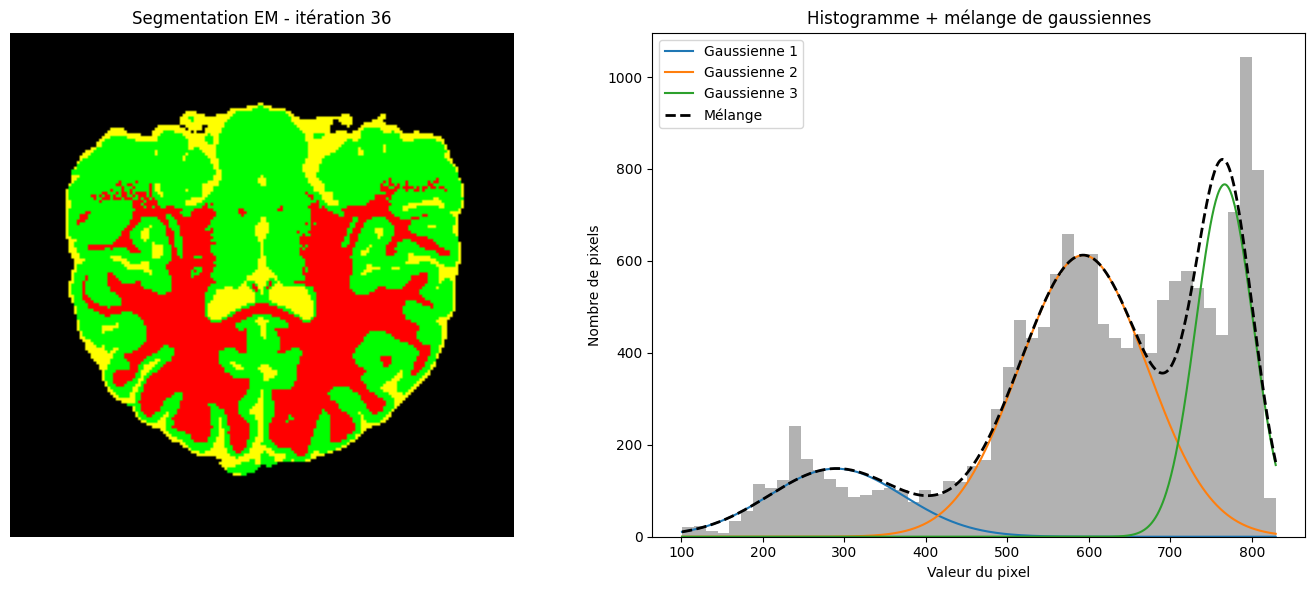

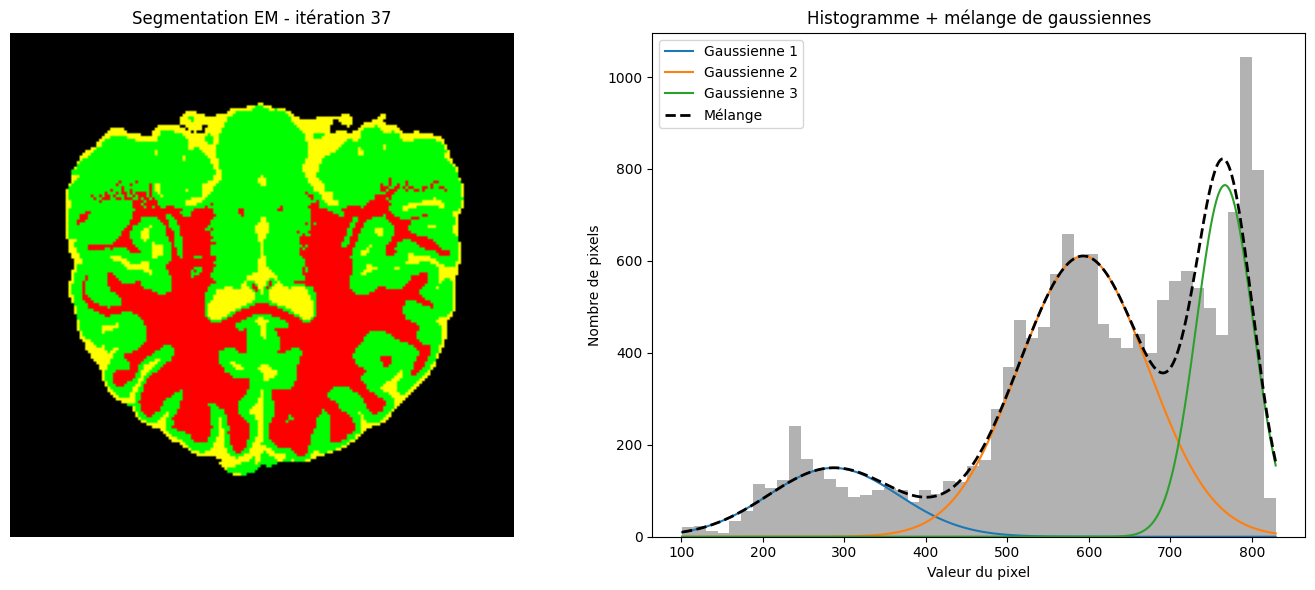

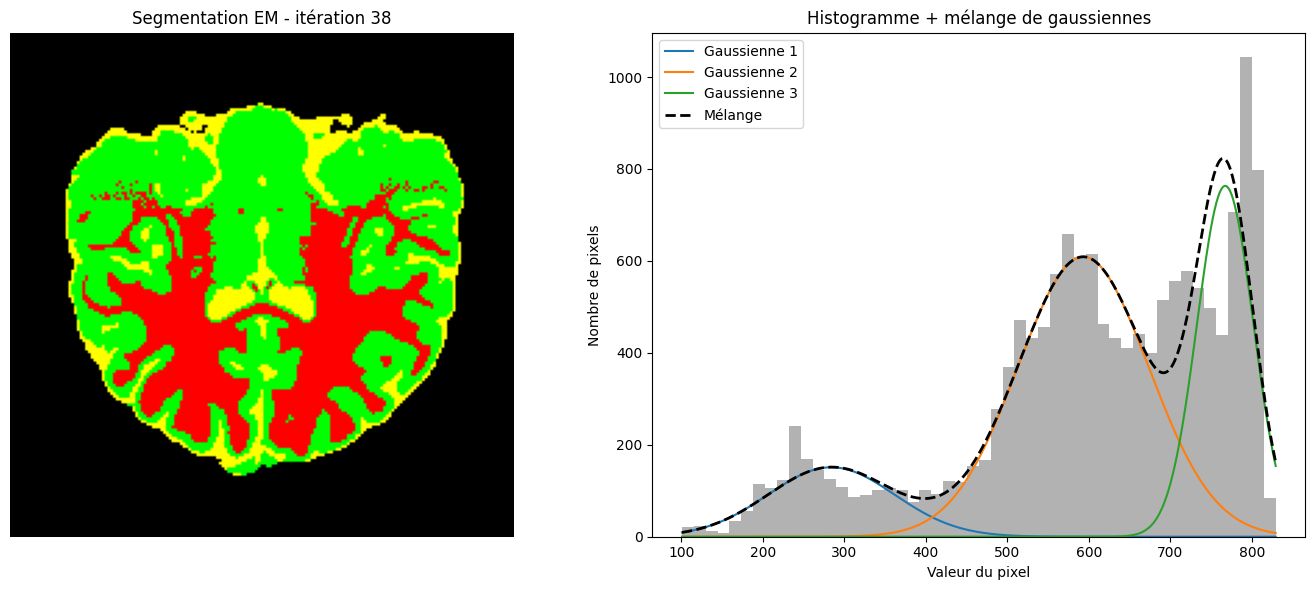

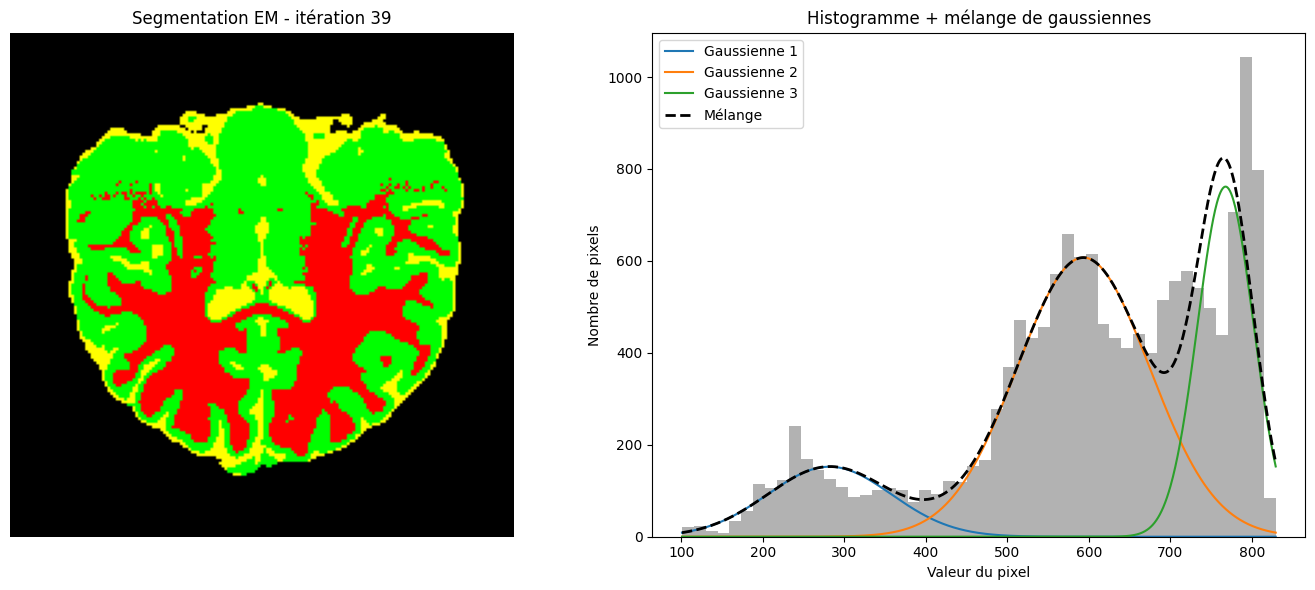

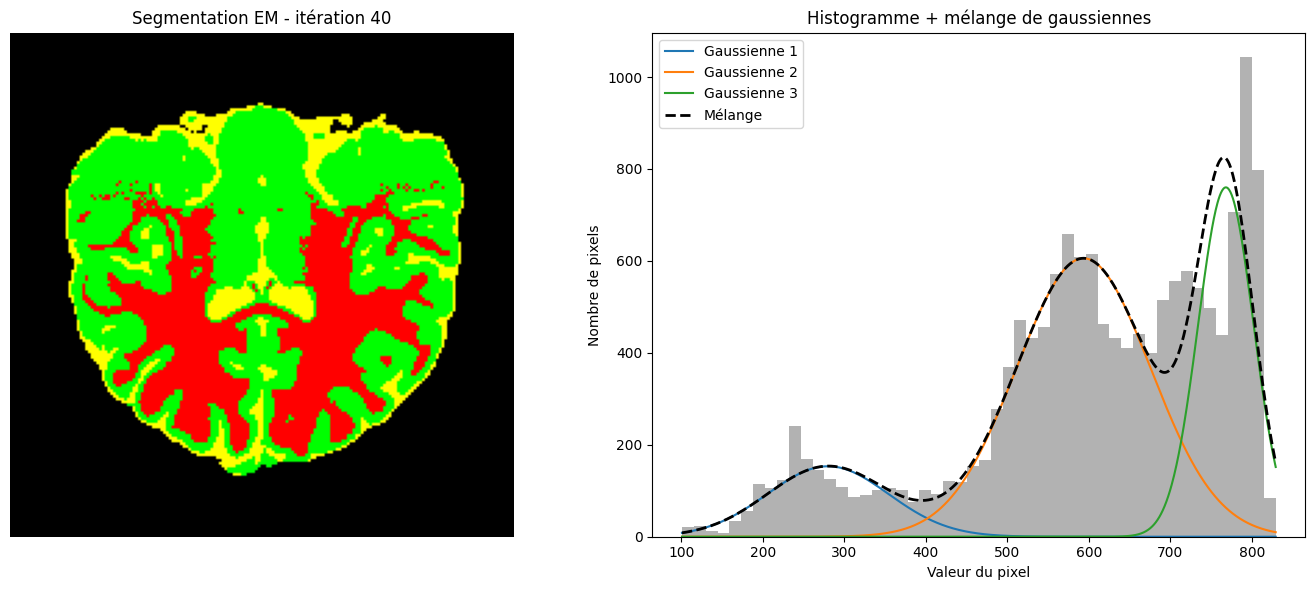

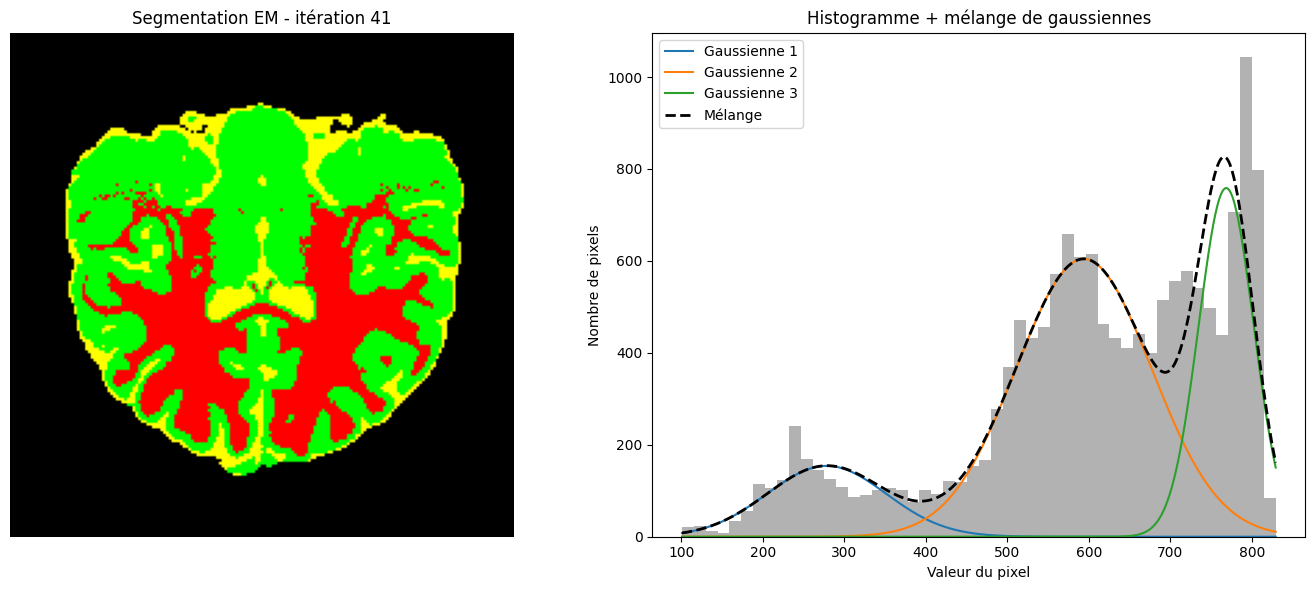

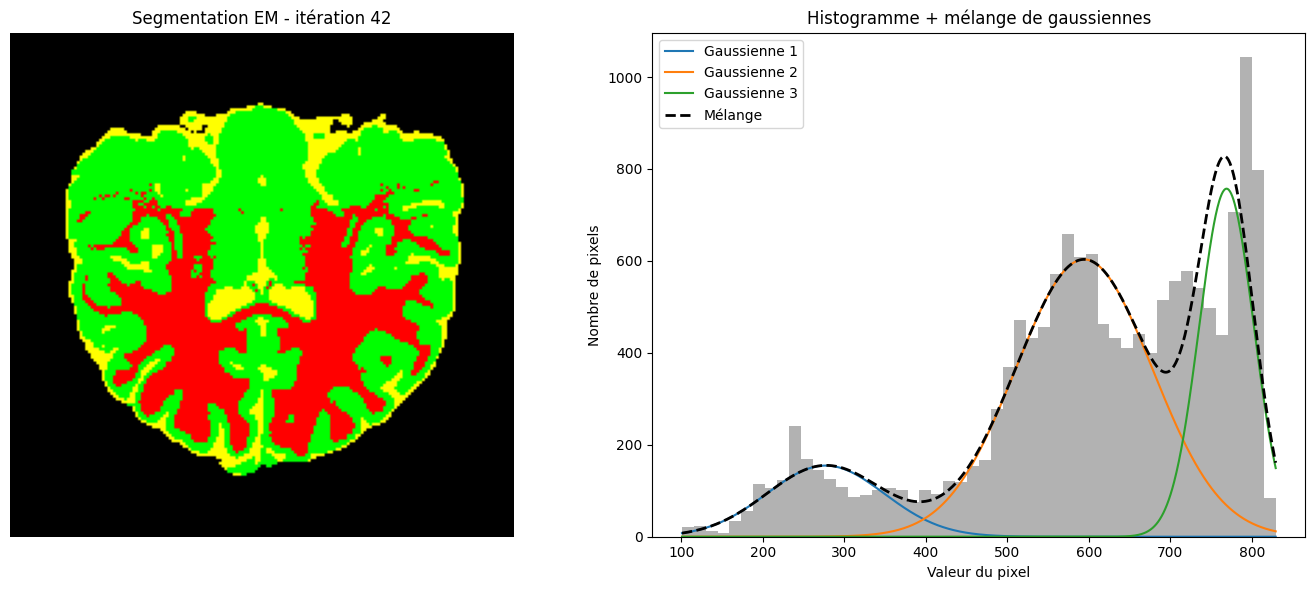

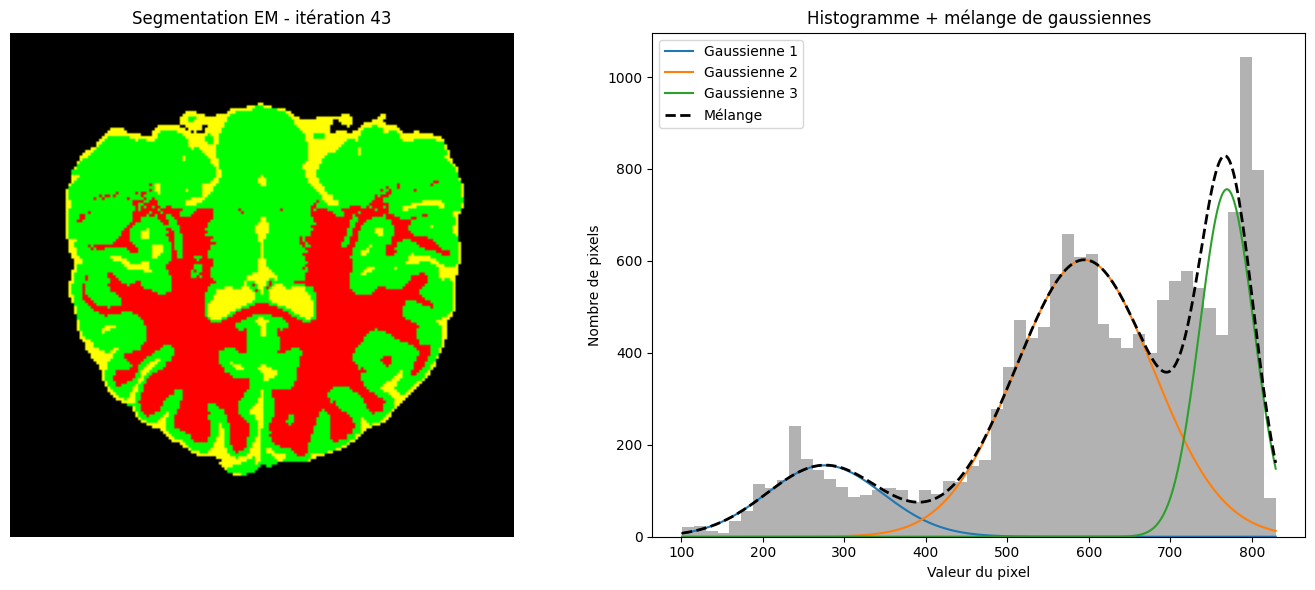

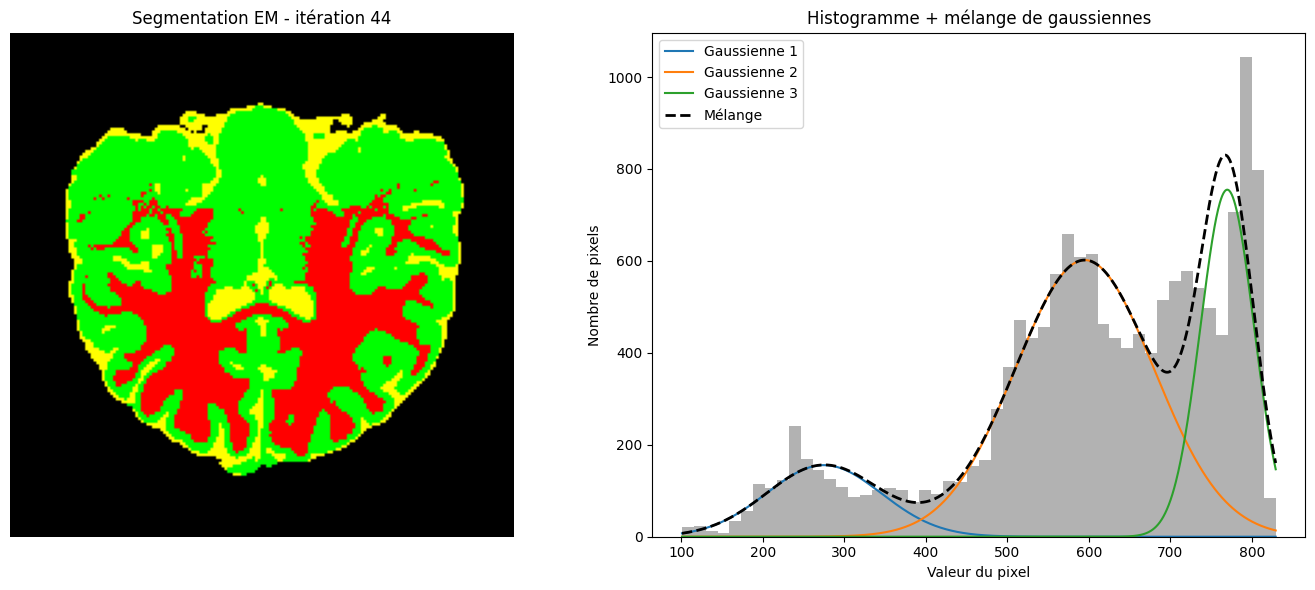

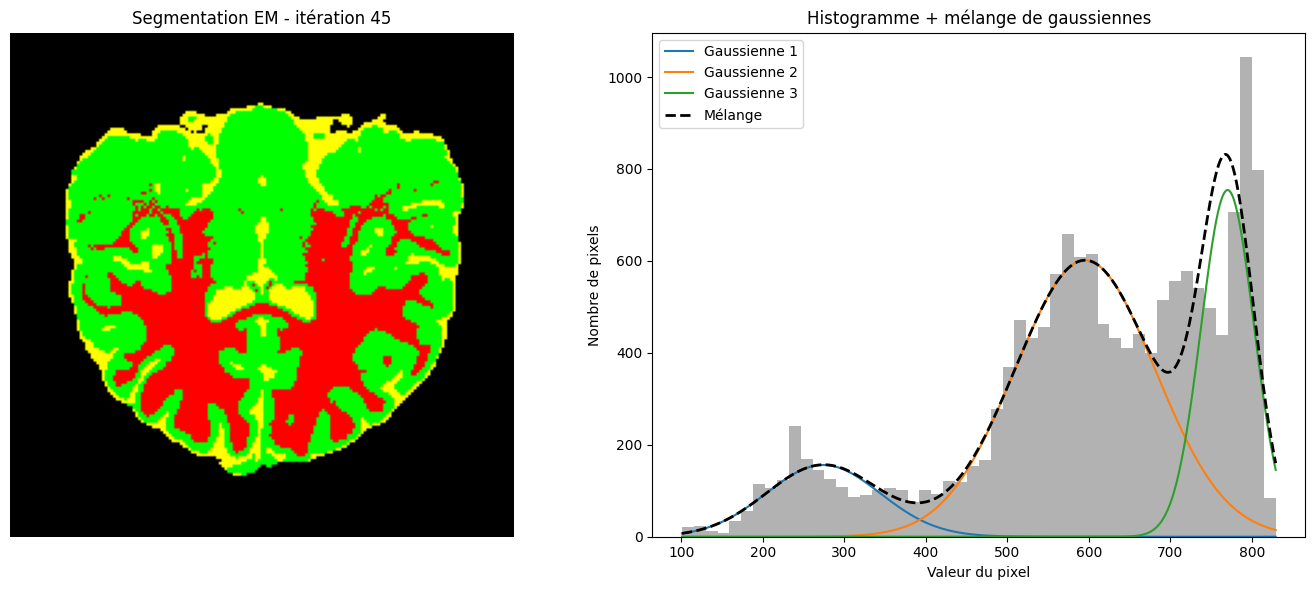

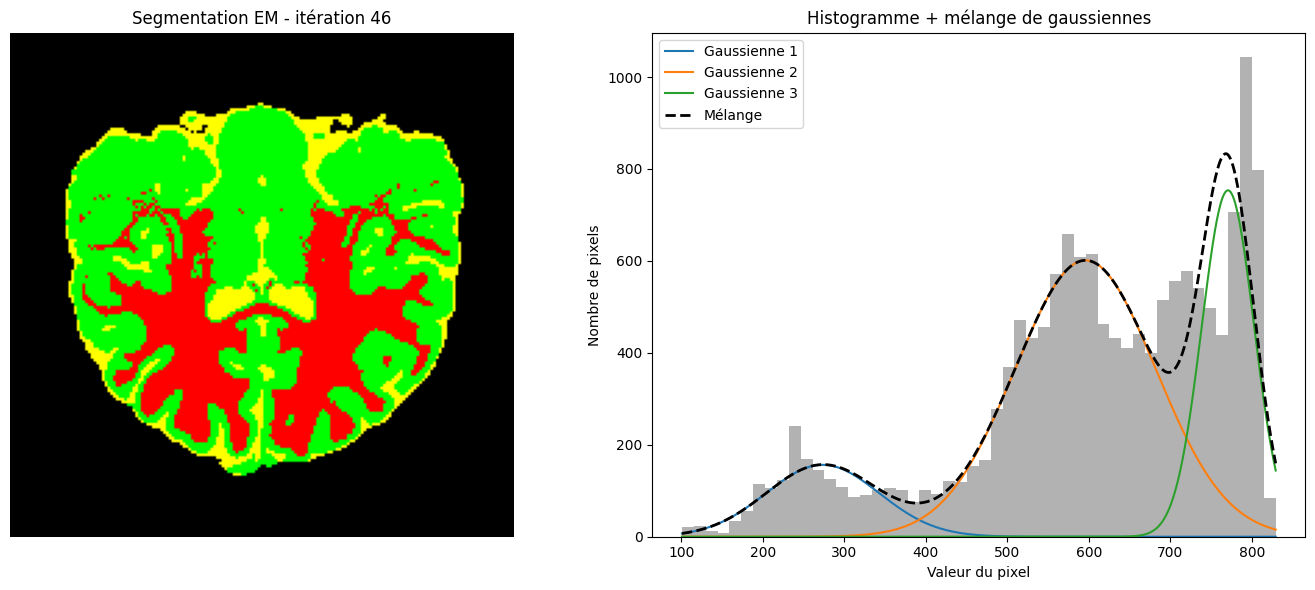

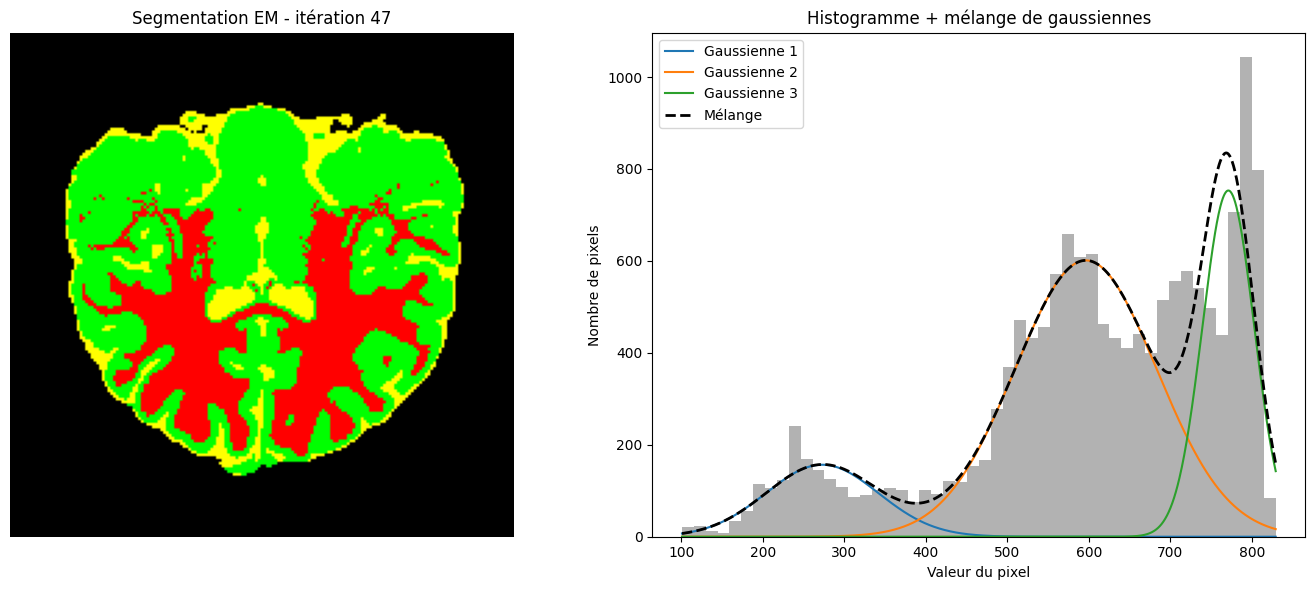

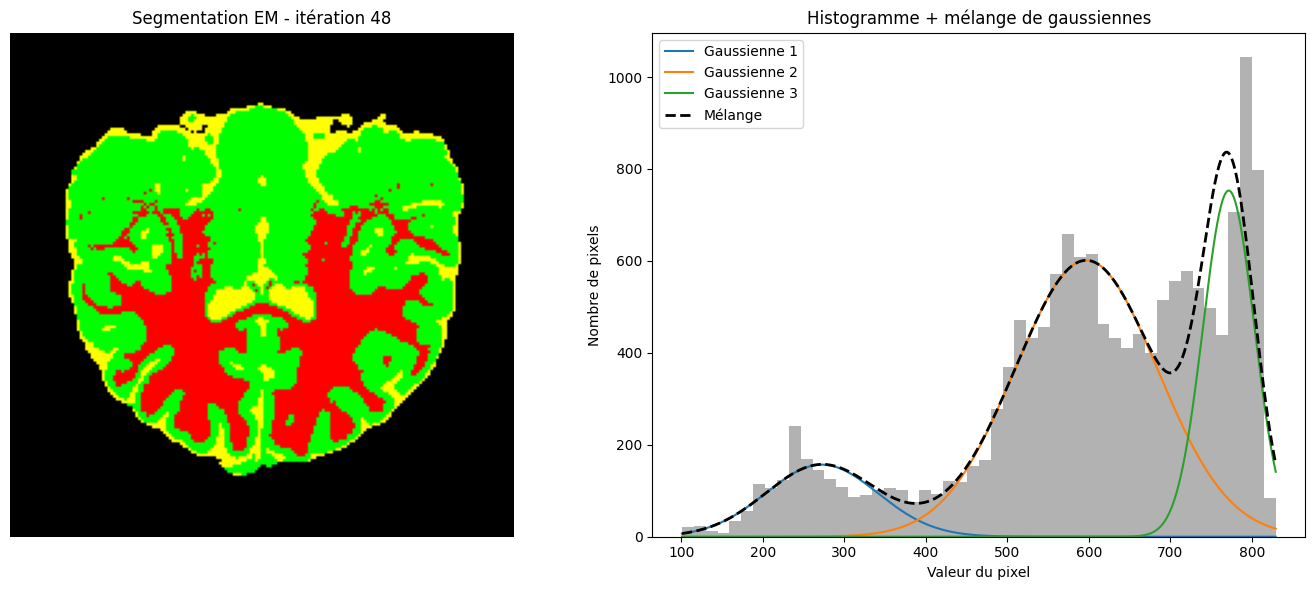

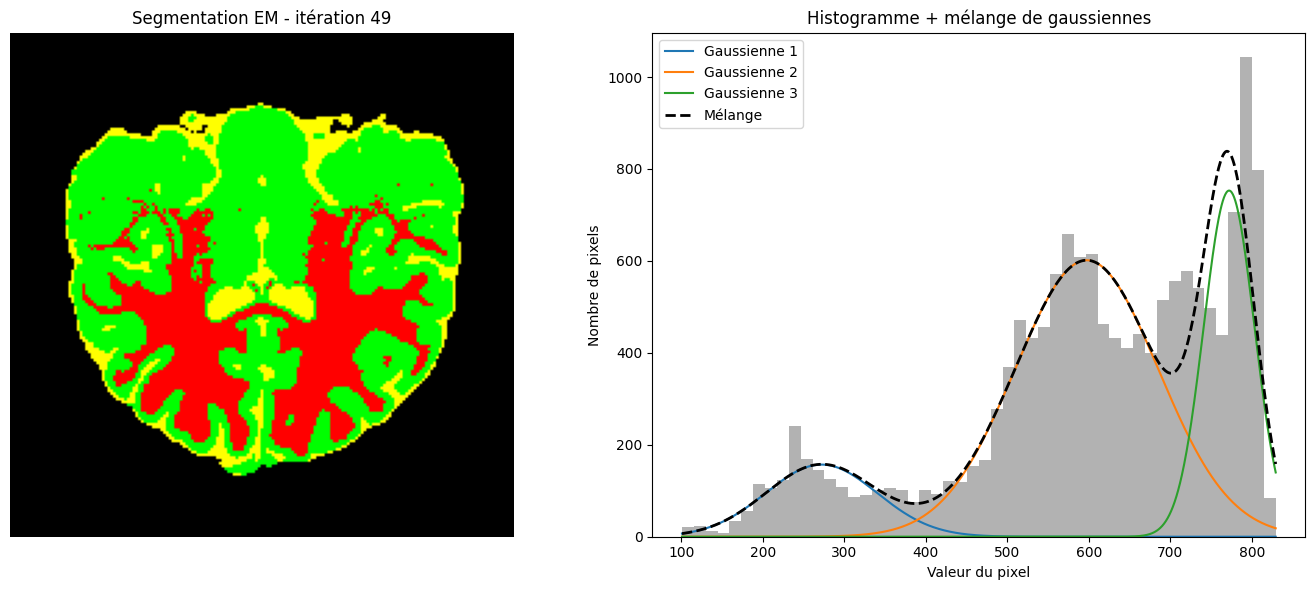

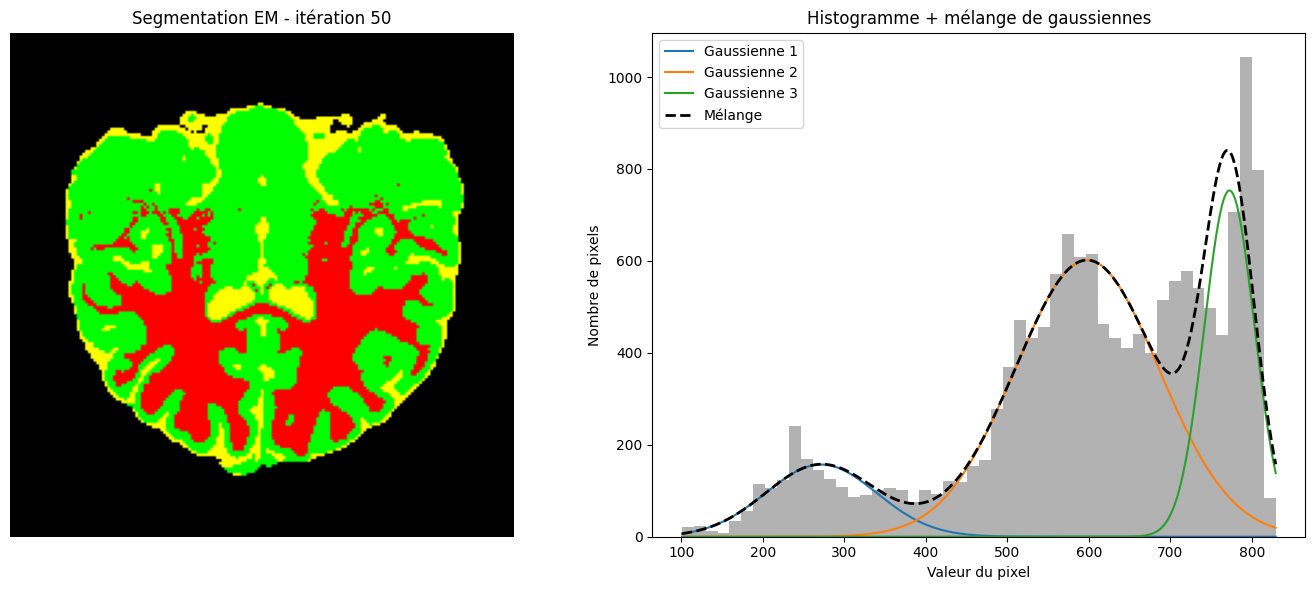

(array([[9.46148641e-01, 5.38513588e-02, 2.59172367e-43],
        [5.19757583e-01, 4.80242417e-01, 9.45250987e-33],
        [9.98404165e-01, 1.59583468e-03, 5.28487060e-61],
        ...,
        [8.49205546e-01, 1.50794454e-01, 1.11482576e-38],
        [1.65204914e-01, 8.34795086e-01, 1.31005348e-27],
        [2.22596470e-02, 9.77740353e-01, 3.69323144e-22]], shape=(14973, 3)),
 array([0.12284506, 0.61031712, 0.26683782]),
 array([271.54407846, 597.89511704, 772.60581556]),
 array([4633.95944817, 7792.89341575,  950.8526951 ]))

In [58]:
em_gmm_image2(brain, brain_mask, 3, 100, 50, epsilon=1e-3)